### 实验1 神经网络原理与实现 (神经网络实现手写数字识别)
（本实验以及后续实验，均使用PyTorch框架，有条件的情况下均使用CUDA训练）
#### 一、基本实现过程
##### 1.1 基本设置
（1）导入torch等第三方库

In [157]:
import random
import numpy as np
import pandas as pd

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset # 数据集组织，以便后面batch划分
import torch.optim as optim # 优化器

（2）设置图表显示

In [158]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker  # 导入刻度格式化模块
plt.rcParams['font.sans-serif'] = ['Noto Sans CJK SC']  # 支持中文字体
plt.rcParams['figure.dpi'] = 300   # Notebook 中显示的清晰度
plt.rcParams['savefig.dpi'] = 300  # 保存图片的清晰度
plt.rcParams['font.size'] = 12

（3）观察设备情况，以便后面使用GPU

In [159]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"正在使用的设备: {device}")

正在使用的设备: cuda


（4）设置固定随机种子，以便复现

In [160]:
# 设置随机种子（不含对batch划分的设置）
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)                # PyTorch CPU随机数
    torch.cuda.manual_seed(seed)           # PyTorch 当前GPU随机数
    torch.cuda.manual_seed_all(seed)       # PyTorch 所有GPU随机数
    torch.backends.cudnn.deterministic = True # 强制CuDNN使用确定性算法
    torch.backends.cudnn.benchmark = False # 关闭CuDNN的自动寻找最优算法

set_seed(42)

##### 1.2 数据导入与预处理
（1）导入数据集并观察形状

In [161]:
# 观察数据集都有哪些文件
data = np.load('mnist.npz')
print(data.files)

['x_test', 'x_train', 'y_train', 'y_test']


In [162]:
# 导入数据，并观察数据形状
x_train, x_test, y_train, y_test = data['x_train'], data['x_test'], data['y_train'], data['y_test']
print(f"训练集特征形状: {x_train.shape}")
print(f"训练集标签形状: {y_train.shape}")
print(f"测试集特征形状: {x_test.shape}")
print(f"测试集标签形状: {y_test.shape}")

训练集特征形状: (60000, 28, 28)
训练集标签形状: (60000,)
测试集特征形状: (10000, 28, 28)
测试集标签形状: (10000,)


（2）数据形状转换与归一化

In [163]:
# 将单条 二维标签数据 转变为 一维数据
x_train = x_train.reshape((60000, 28 * 28))
x_test = x_test.reshape((10000, 28 * 28))
print(f"训练集特征形状: {x_train.shape}")
print(f"测试集特征形状: {x_test.shape}")

# 数据范围仅[0, 255]，故除以255即可归一化
x_train = x_train.astype('float32') / 255
x_test = x_test.astype('float32') / 255

# 另外，torch框架下，无需对无序类别标签作one-hot处理

训练集特征形状: (60000, 784)
测试集特征形状: (10000, 784)


（3）转换后的数据，转变为torch的张量

In [164]:
# 将特征、标签等数据，转换为torch中的张量
x_train_tensor = torch.tensor(x_train, dtype = torch.float32).to(device)
x_test_tensor = torch.tensor(x_test, dtype = torch.float32).to(device)

y_train_tensor = torch.tensor(y_train, dtype = torch.long).to(device) # 无序类别标签，类型必须是torch.long
y_test_tensor = torch.tensor(y_test, dtype = torch.long).to(device)

##### 1.3 网络结构定义与模型训练

Baseline参数汇总：

| **参数** | 输入层 | 隐藏层 (1层) | 输出层 | 激活函数 | dropout | epoch | batch | 学习率 | 优化器 | loss函数 |
|:---:| :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: |
| **值** | 28*28=784 | 512 | 10 | relu | 不设置 | 15 | 128 | 0.001 | RMSprop | 交叉熵损失 |

（1）网络结构定义

In [165]:
# 自定义网络结构
class Net(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(784, 512) # 输入层 784 -> 隐藏层 512
        self.out = nn.Linear(512, 10) # 隐藏层 512 -> 输出层 10
        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.out(x)  # 直接输出线性结果
        return x

（2）创建model对象，设置loss函数与优化器

In [166]:
model = Net() # 定义模型
criterion = nn.CrossEntropyLoss() # 损失函数（交叉熵损失）
optimizer = optim.RMSprop(model.parameters(), lr = 0.001) # 优化器

（3）训练模型，并评估每epoch的结果

In [167]:
# 训练模型，并在每轮epoch后，针对训练数据评估模型
def train_model(model, epochs, batch):
    # 将模型迁移到GPU训练
    model = model.to(device)

    # 全数据集分batch
    g = torch.Generator()
    g.manual_seed(42) # 为了可复现，为batch划分也设置固定随机种子
    
    train_dataset = TensorDataset(x_train_tensor, y_train_tensor) # 特征与标签，一起构造成torch张量数据集
    train_dataloader = DataLoader(train_dataset, batch_size=batch, shuffle=True, generator=g) # 将数据集组织成 以batch加载 的形式
    
    loss_result = []

    for epoch in range(epochs):
        train_total_loss_sum = 0.0  # 记录每个epoch的总损失
        train_num = 0   # 记录训练集的总样本数

        model.train() # 设置为训练模式
        for batch_x, batch_y in train_dataloader:
            optimizer.zero_grad() # 梯度清零
            preds_y = model(batch_x) # 前向传播
            loss_train = criterion(preds_y, batch_y) # 计算损失
            loss_train.backward() # 反向传播（自动求导 并 累加梯度）
            optimizer.step() # 根据求导计算出的 梯度，更新模型参数

            train_total_loss_sum += loss_train.item() * batch_y.size(0) # 为便于最后计算总平均loss，通过乘以batch样本数，加和单batch下的loss总和
            train_num += batch_y.size(0)

        train_correct = 0
        
        model.eval() # 设置为评估模式
        with torch.no_grad(): # 关闭梯度计算，节省内存
            for batch_x, batch_y in train_dataloader:
                train_preds = model(batch_x) # 前向传播                
                predicted_classes = torch.argmax(train_preds, dim=1) # 将概率最大的标签值，作为预测结果
                train_correct += (predicted_classes == batch_y).sum().item() # 统计预测正确的样本数
        
        loss_result.append([f"{epoch + 1}/{epochs}", train_total_loss_sum / train_num, train_correct / train_num]) # 记录每epoch的loss与Acc
        # print(f"训练进度: {epoch+1}/{epochs}, 训练集loss: {train_total_loss_sum / train_num:.4f}, 训练集Acc: {train_correct / train_num * 100:.2f}%  ({train_correct}/{train_num})")

    result_df = pd.DataFrame(loss_result, columns=['Epoch', 'Loss', 'Acc'])
    return result_df

In [168]:
train_result_df = train_model(model, epochs=15, batch = 128)
train_result_df.style.format({'Acc': '{:.2%}'}).hide(axis = 'index')

Epoch,Loss,Acc
1/15,0.255070,96.36%
2/15,0.107386,97.84%
3/15,0.070626,98.52%
4/15,0.050738,99.00%
5/15,0.037050,98.58%
6/15,0.027418,99.53%
7/15,0.020810,99.60%
8/15,0.016088,99.74%
9/15,0.011537,99.79%
10/15,0.008931,99.83%


（4）绘制Baseline的loss与Acc曲线，查看收敛情况

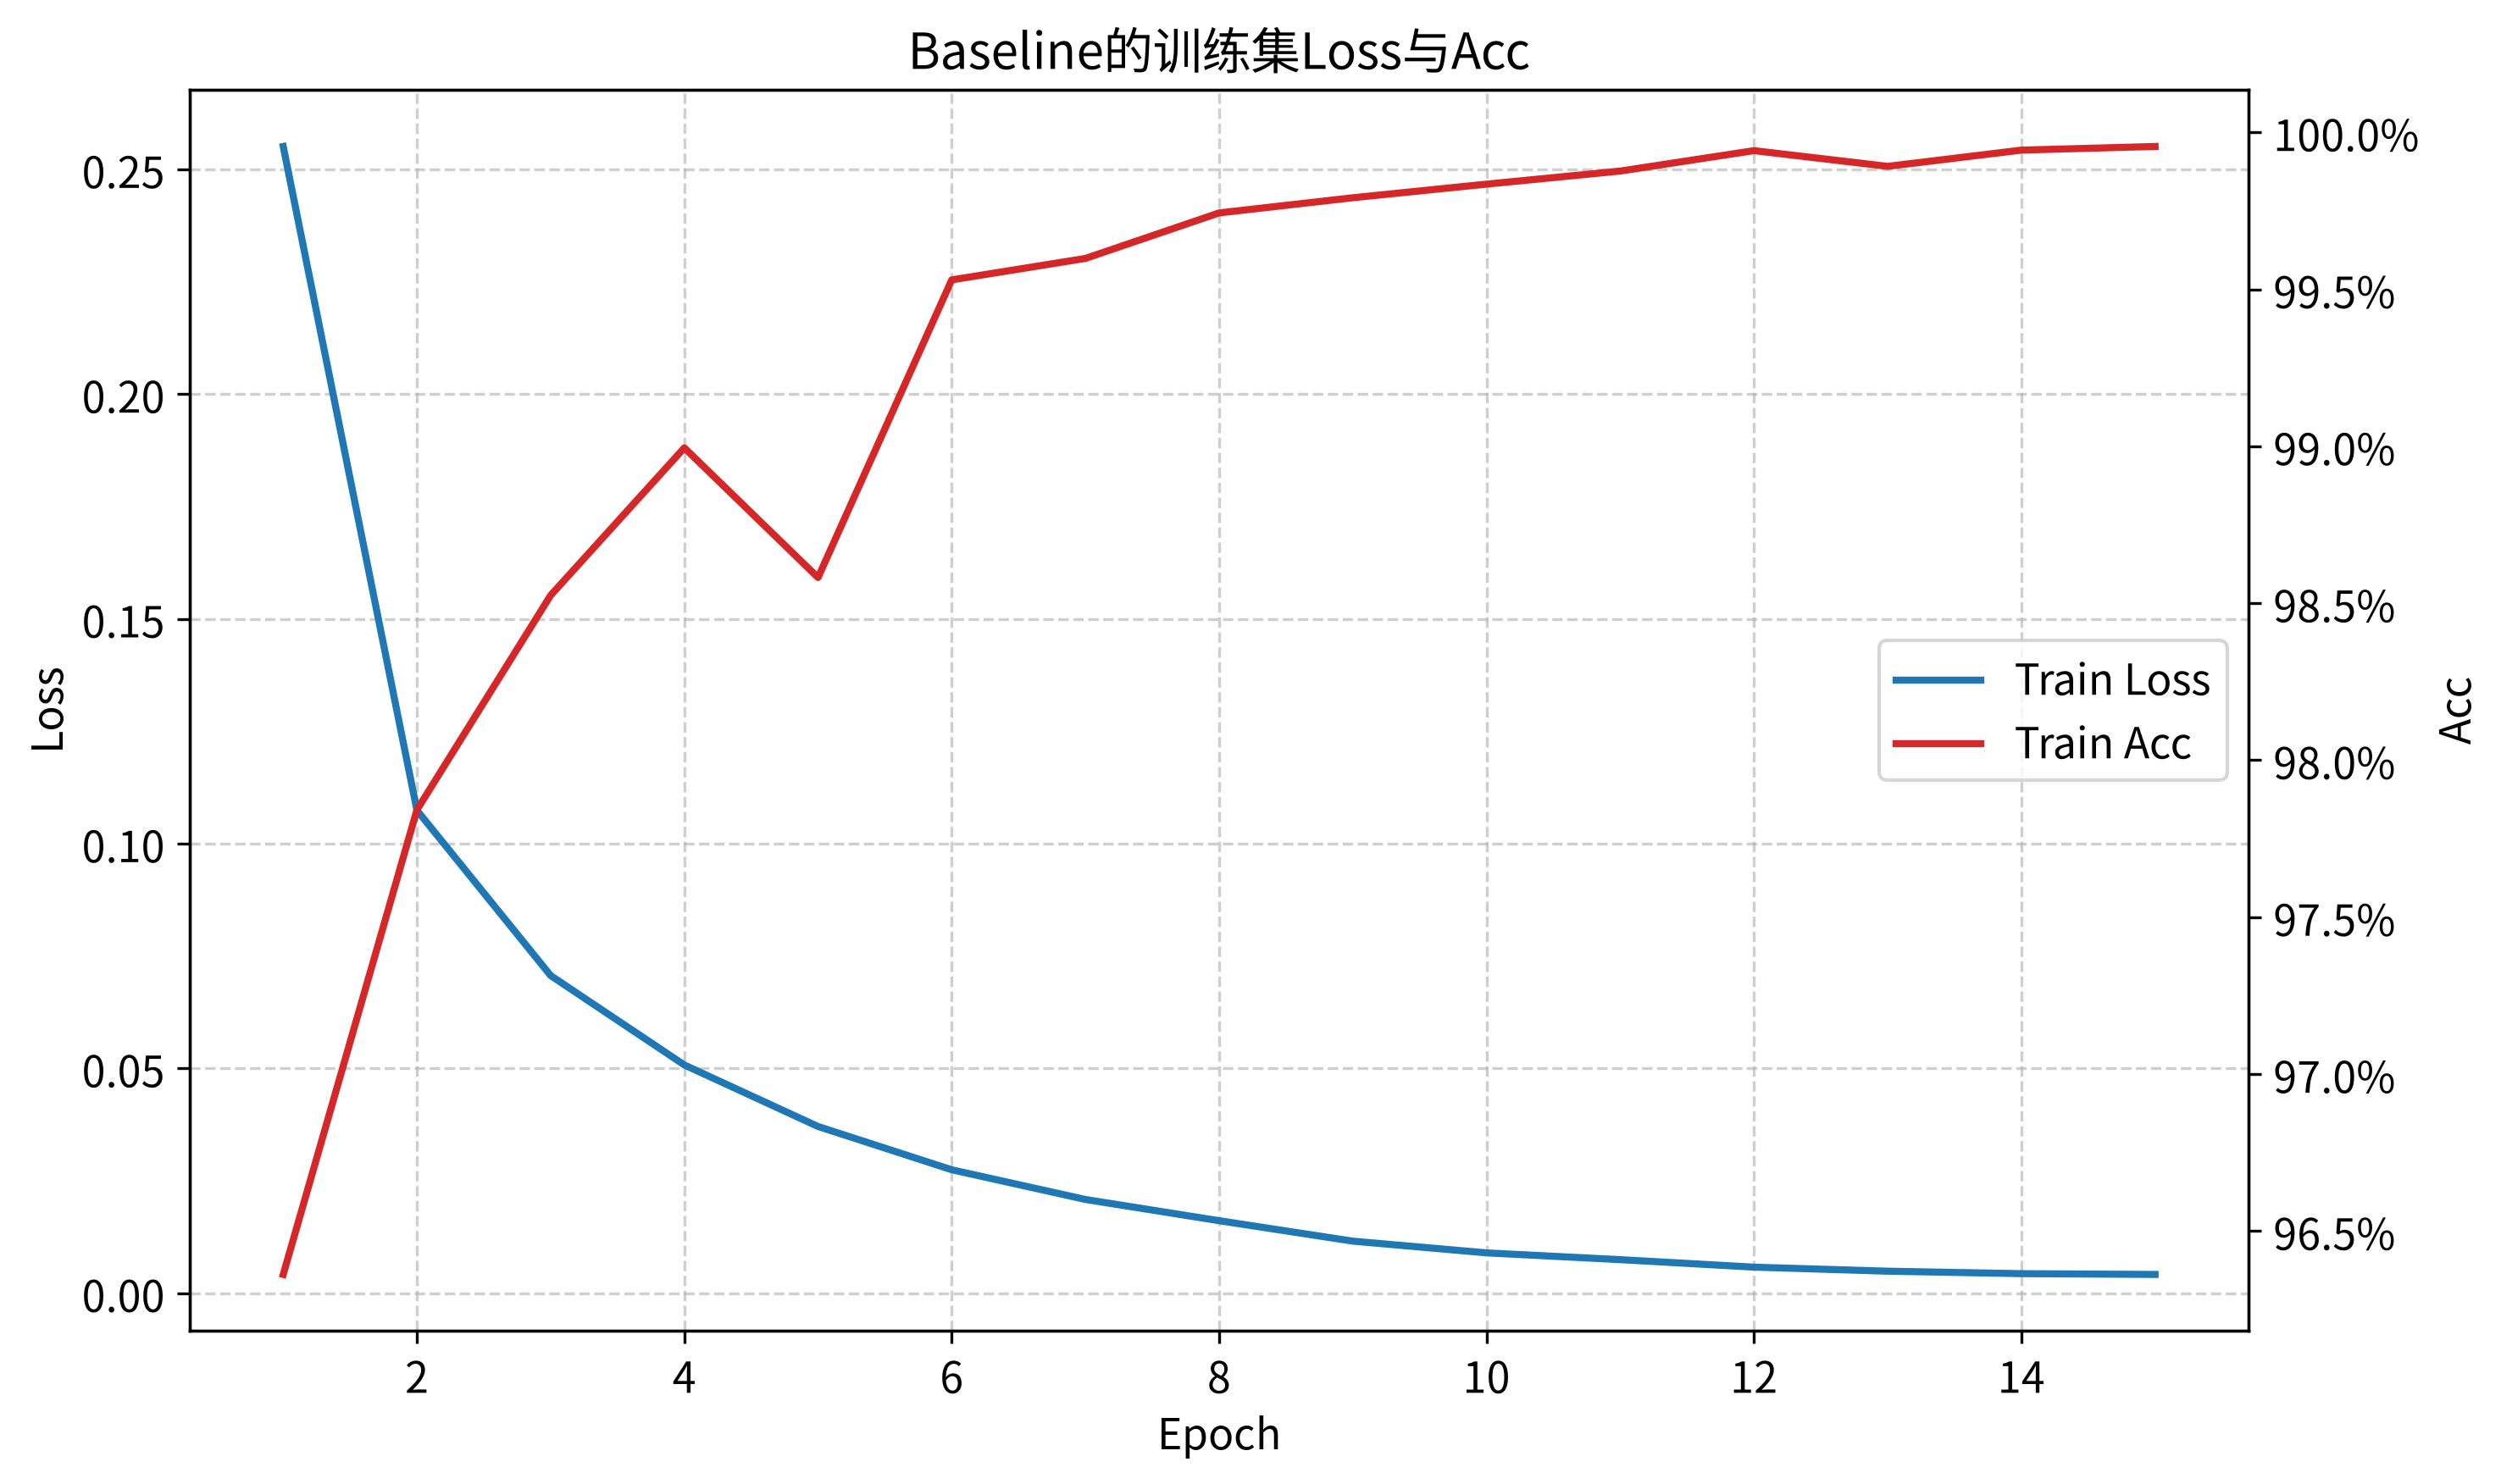

In [169]:
# 从结果列表中提取 loss 和 acc 数据
losses = train_result_df['Loss']
accs = train_result_df['Acc']
epochs = range(1, len(losses) + 1)

# 初始化画布
fig, ax1 = plt.subplots(figsize=(10, 6)) # ax1 作为左侧主坐标轴

# 绘制左侧Loss（蓝线）
color_loss = 'tab:blue'
line1 = ax1.plot(epochs, losses, label='Train Loss', color=color_loss, linewidth=2)
ax1.set_xlabel('Epoch', fontsize=12)
ax1.set_ylabel('Loss', fontsize=12)
ax1.tick_params(axis='y') # 刻度线颜色与线条一致
ax1.grid(True, linestyle='--', alpha=0.6) # 加网格

# 绘制右侧Acc（红线）
ax2 = ax1.twinx()  
color_acc = 'tab:red'
line2 = ax2.plot(epochs, accs, label='Train Acc', color=color_acc, linewidth=2)
ax2.set_ylabel('Acc', fontsize=12)
ax2.tick_params(axis='y')

ax2.yaxis.set_major_formatter(ticker.PercentFormatter(xmax=1.0, decimals=1)) # 将Acc轴格式化为百分比

# 合并图例
lines = line1 + line2
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='center right', fontsize=12)

# 设置标题并显示
plt.title('Baseline的训练集Loss与Acc', fontsize=14)
plt.tight_layout()
plt.show()

In [170]:
# 在测试集上评估模型并预测
def evaluate_model(model, batch):
    model.eval() # 将模型切换到测试状态
    test_correct = 0
    test_num = 0
    test_total_loss_sum = 0.0

    test_result = []
    test_probs = []

    # 同样分batch进行测试
    test_dataset = TensorDataset(x_test_tensor, y_test_tensor)
    test_dataloader = DataLoader(test_dataset, batch_size=batch, shuffle=False)

    with torch.no_grad(): # 关闭梯度计算，节省内存
        for batch_x, batch_y in test_dataloader:
            test_preds = model(batch_x) # 前向传播
            loss = criterion(test_preds, batch_y) # 计算单batch的平均loss
            test_total_loss_sum += loss.item() * batch_y.size(0) # 为便于最后计算总平均loss，通过乘以batch样本数，加和单batch下的loss总和
            
            predicted_classes = torch.argmax(test_preds, dim=1) # 将概率最大的标签值，作为预测结果
            test_correct += (predicted_classes == batch_y).sum().item() # 统计预测正确的样本数
            test_num += batch_y.size(0) # 统计测试集总样本数

            test_result += predicted_classes.tolist() # 追加预测结果（argmax 概率）
            test_probs += torch.softmax(test_preds, dim=1).tolist() # 追加每个数字的预测概率

    avg_test_loss = test_total_loss_sum / test_num  # 计算总平均loss
    accuracy = test_correct / test_num    # 计算Acc

    print(f"测试集loss: {avg_test_loss:.4f}")
    print(f"测试集Acc: {accuracy * 100:.2f}%  ({test_correct}/{test_num})")

    # 预测结果
    result_df = pd.DataFrame(test_result, columns=['Predict'])
    # 预测该数字为0-9的原始概率
    prob_columns = [f'Prob_{i}' for i in range(10)] 
    prob_df = pd.DataFrame(test_probs, columns=prob_columns)
    # 合并成一个df
    result_df = pd.concat([result_df, prob_df], axis=1)
    
    return result_df

In [171]:
test_result = evaluate_model(model, batch=128)
test_result.round(4)

测试集loss: 0.0742
测试集Acc: 98.20%  (9820/10000)


,Predict,Prob_0,Prob_1,Prob_2,Prob_3,Prob_4,Prob_5,Prob_6,Prob_7,Prob_8,Prob_9
0,7,0.0,0.0000,0.0,0.0001,0.0000,0.0,0.0,0.9999,0.0000,0.0000
1,2,0.0,0.0000,1.0,0.0000,0.0000,0.0,0.0,0.0000,0.0000,0.0000
2,1,0.0,0.9999,0.0,0.0000,0.0000,0.0,0.0,0.0000,0.0001,0.0000
3,0,1.0,0.0000,0.0,0.0000,0.0000,0.0,0.0,0.0000,0.0000,0.0000
4,4,0.0,0.0000,0.0,0.0000,0.9995,0.0,0.0,0.0000,0.0000,0.0005
...,...,...,...,...,...,...,...,...,...,...,...
9995,2,0.0,0.0000,1.0,0.0000,0.0000,0.0,0.0,0.0000,0.0000,0.0000
9996,3,0.0,0.0000,0.0,1.0000,0.0000,0.0,0.0,0.0000,0.0000,0.0000
9997,4,0.0,0.0000,0.0,0.0000,1.0000,0.0,0.0,0.0000,0.0000,0.0000
9998,5,0.0,0.0000,0.0,0.0000,0.0000,1.0,0.0,0.0000,0.0000,0.0000


#### 二、参数调整与对比
##### 2.1 隐藏层数

（1）修改网络结构如下，将隐藏层数调整为2与3，并定义新增隐藏层的结构一致

In [172]:
# 2个隐藏层的网络结构
class MultipleHiddenNet_2(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(784, 512) # 输入层 784 -> 隐藏层1 512
        self.fc2 = nn.Linear(512, 512) # 隐藏层1 512 -> 隐藏层2 512
        self.out = nn.Linear(512, 10) # 隐藏层2 512 -> 输出层 10
        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        x = self.out(x)  # 直接输出线性结果
        return x

# 3个隐藏层的网络结构
class MultipleHiddenNet_3(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(784, 512) # 输入层 784 -> 隐藏层1 512
        self.fc2 = nn.Linear(512, 512) # 隐藏层1 512 -> 隐藏层2 512
        self.fc3 = nn.Linear(512, 512) # 隐藏层2 512 -> 隐藏层3 512
        self.out = nn.Linear(512, 10) # 隐藏层3 512 -> 输出层 10
        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        x = self.relu(self.fc3(x))
        x = self.out(x)  # 直接输出线性结果
        return x

（2）2个隐藏层结构的训练与评估

In [173]:
model = MultipleHiddenNet_2() # 定义模型
criterion = nn.CrossEntropyLoss() # 损失函数（交叉熵损失）
optimizer = optim.RMSprop(model.parameters(), lr = 0.001) # 优化器

train_result_df1 = train_model(model, epochs=15, batch = 128)
train_result_df1.style.format({'Acc': '{:.2%}'}).hide(axis = 'index')

Epoch,Loss,Acc
1/15,0.229900,97.02%
2/15,0.083026,98.17%
3/15,0.054733,98.13%
4/15,0.039263,99.02%
5/15,0.027906,99.14%
6/15,0.022003,99.63%
7/15,0.018932,99.48%
8/15,0.015890,99.73%
9/15,0.013408,99.57%
10/15,0.011864,99.63%


In [174]:
test_result_df1 = evaluate_model(model, batch=128)
test_result_df1.round(4)

测试集loss: 0.1407
测试集Acc: 97.87%  (9787/10000)


,Predict,Prob_0,Prob_1,Prob_2,Prob_3,Prob_4,Prob_5,Prob_6,Prob_7,Prob_8,Prob_9
0,7,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
1,2,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,1,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,4,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...
9995,2,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
9996,3,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
9997,4,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
9998,5,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0


（3）3个隐藏层结构的训练与评估

In [175]:
model = MultipleHiddenNet_3() # 定义模型
criterion = nn.CrossEntropyLoss() # 损失函数（交叉熵损失）
optimizer = optim.RMSprop(model.parameters(), lr = 0.001) # 优化器

train_result_df2 = train_model(model, epochs=15, batch = 128)
train_result_df2.style.format({'Acc': '{:.2%}'}).hide(axis = 'index')

Epoch,Loss,Acc
1/15,0.260681,96.73%
2/15,0.089368,98.21%
3/15,0.062028,98.40%
4/15,0.047601,98.75%
5/15,0.035896,99.09%
6/15,0.028982,99.33%
7/15,0.025034,99.30%
8/15,0.021277,99.58%
9/15,0.019403,99.69%
10/15,0.014980,99.68%


In [176]:
test_result_df2 = evaluate_model(model, batch=128)
test_result_df2.round(4)

测试集loss: 0.1117
测试集Acc: 98.15%  (9815/10000)


,Predict,Prob_0,Prob_1,Prob_2,Prob_3,Prob_4,Prob_5,Prob_6,Prob_7,Prob_8,Prob_9
0,7,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
1,2,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,1,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,4,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...
9995,2,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
9996,3,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
9997,4,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
9998,5,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0


（4）对比结果可视化

In [177]:
# 不同模型训练结果对比可视化（后面的实验将复用该函数）
def plot_multiple_models_train_result(results_dict, title):
    # 初始化画布：1行2列，共享X轴
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6), sharex=True)
    
    # 定义不同模型线条的颜色
    colors = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red', 'tab:purple']
    
    # 遍历字典，绘制每个模型的曲线
    for i, (model_name, df) in enumerate(results_dict.items()):
        color = colors[i % len(colors)] # 循环使用颜色
        
        # 提取数据
        epochs = range(1, len(df) + 1)
        losses = df['Loss']
        accs = df['Acc']
        
        ax1.plot(epochs, losses, label=model_name, color=color, linewidth=2) # 左图Loss
        ax2.plot(epochs, accs, label=model_name, color=color, linewidth=2) # 右图Acc

    # 设置左图Loss
    ax1.set_title('训练集 Loss', fontsize=14)
    ax1.set_xlabel('Epoch', fontsize=12)
    ax1.set_ylabel('Loss', fontsize=12)
    ax1.grid(True, linestyle='--', alpha=0.6)
    ax1.legend(fontsize=12) # 左侧图例

    # 设置右图Acc
    ax2.set_title('训练集 Acc', fontsize=14)
    ax2.set_xlabel('Epoch', fontsize=12)
    ax2.set_ylabel('Acc', fontsize=12)
    ax2.grid(True, linestyle='--', alpha=0.6)
    ax2.legend(fontsize=12) # 右侧图例
    
    # 右图纵轴格式化为百分比
    ax2.yaxis.set_major_formatter(ticker.PercentFormatter(xmax=1.0, decimals=1))

    # 全局设置与显示
    fig.suptitle(title, fontsize=16) # 总标题
    plt.tight_layout()
    plt.show()

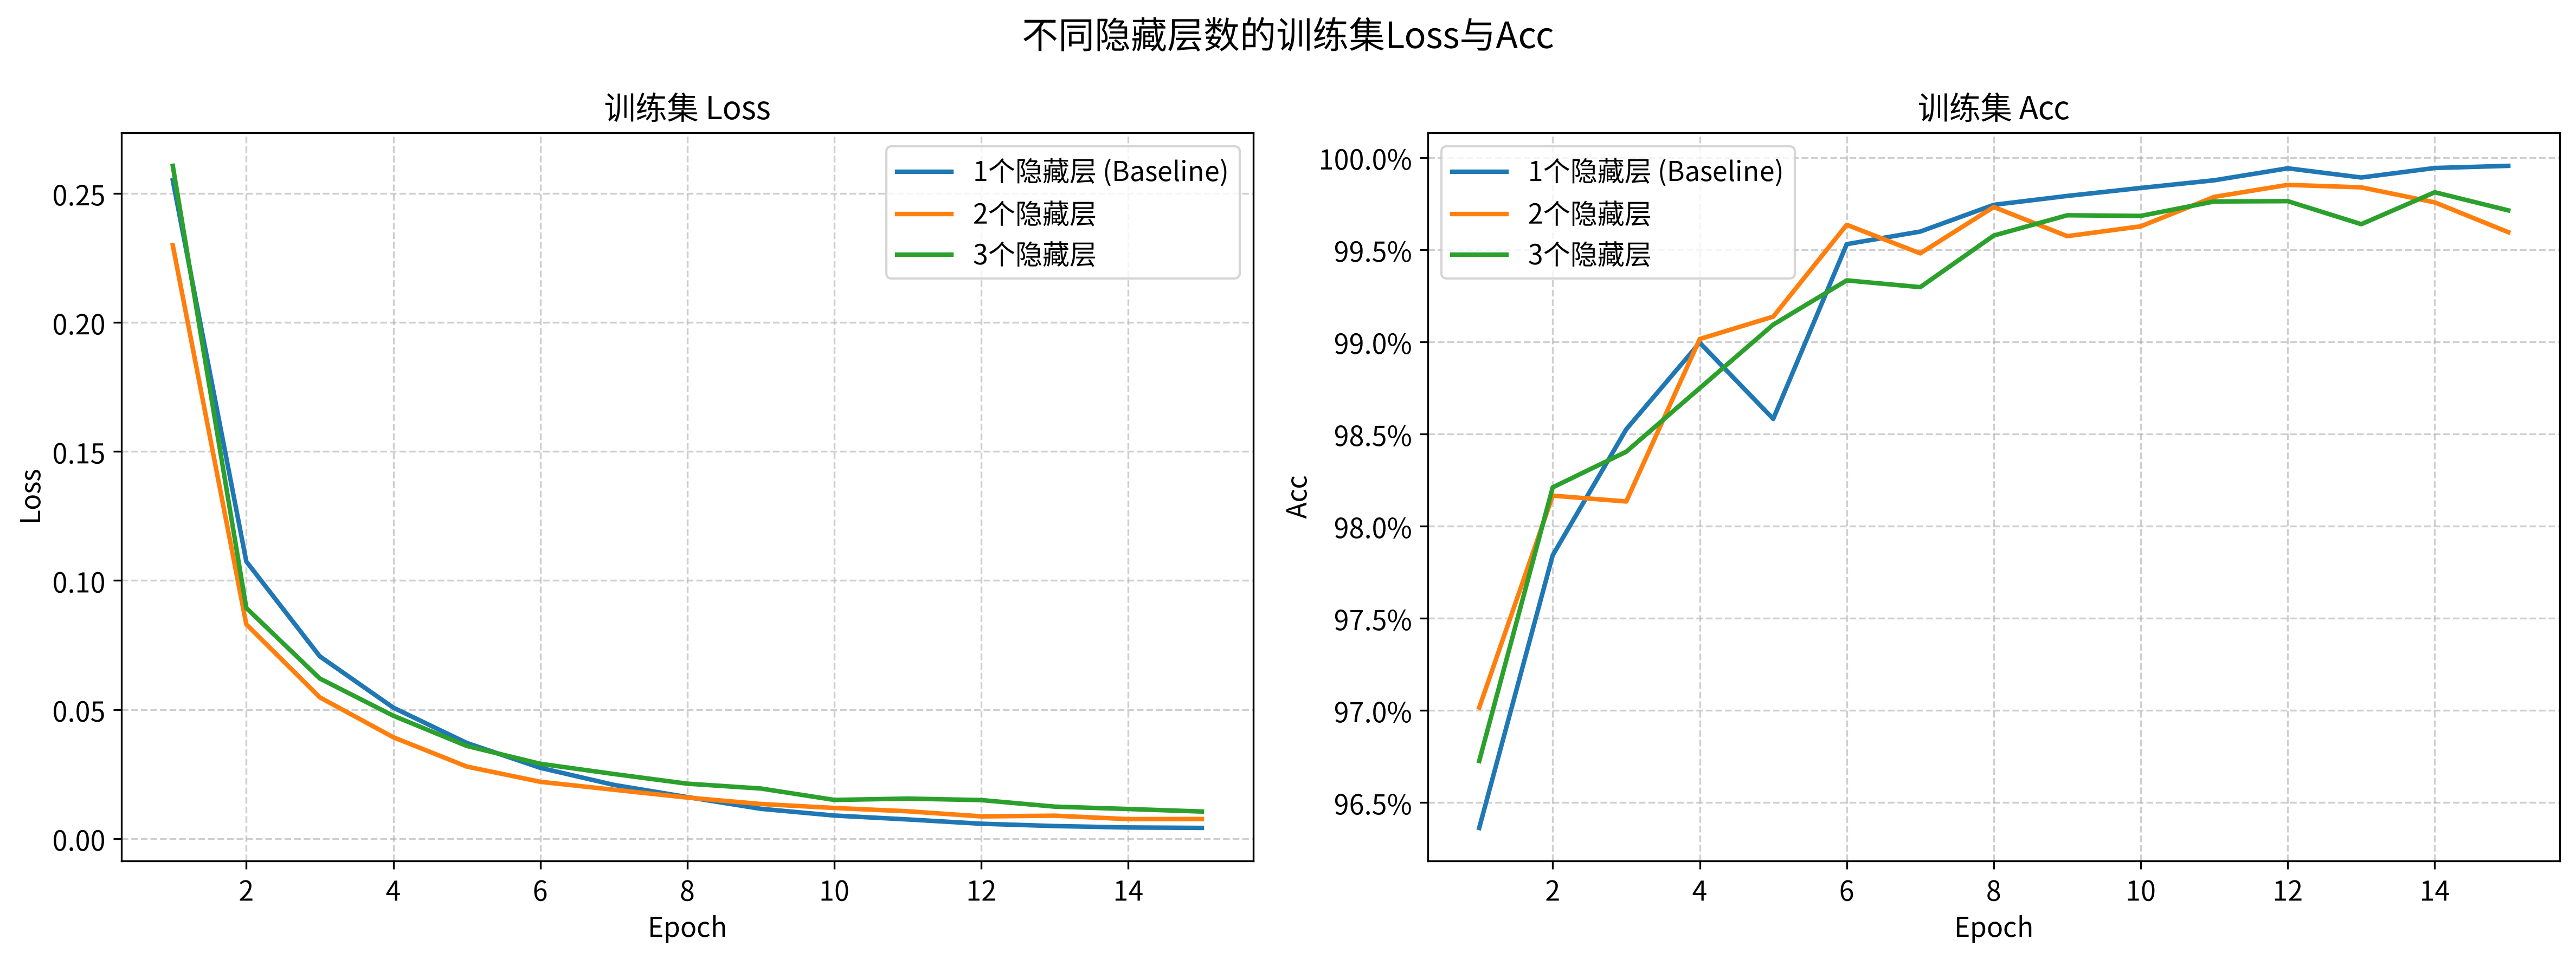

In [178]:
compare_data = {
    '1个隐藏层 (Baseline)': train_result_df,
    '2个隐藏层': train_result_df1,
    '3个隐藏层': train_result_df2
}
plot_multiple_models_train_result(compare_data, title="不同隐藏层数的训练集Loss与Acc")

测试集结果对比：

| | Baseline (1 hidden layer) | 2 hidden layers | 3 hidden layers |
| :---: | :---: | :---: | :---: |
| Loss | 0.0742 | 0.1407 | 0.1117 |
| Acc | **98.20%** | 97.87% | 98.15% |

结论：手写数字识别的较简单任务，使用多层隐藏层等较复杂结构，可能导致过拟合。


##### 2.2 隐藏层神经元(单元)数
（1）修改网络结构如下：创建模型时，隐藏层单元数需要自己定义，隐藏层数保持为1

In [179]:
# 可调整隐藏层单元数的网络结构
class HiddenNumNet(nn.Module):
    def __init__(self, hidden_num):
        super().__init__()
        self.fc1 = nn.Linear(784, hidden_num) # 输入层 784 -> 隐藏层 hidden_num
        self.out = nn.Linear(hidden_num, 10) # 隐藏层 hidden_num -> 输出层 10
        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.out(x)  # 直接输出线性结果
        return x

（2）将隐藏层单元数调整为64

In [180]:
model = HiddenNumNet(hidden_num = 64) # 将隐藏层单元数调整为64
criterion = nn.CrossEntropyLoss() # 损失函数（交叉熵损失）
optimizer = optim.RMSprop(model.parameters(), lr = 0.001) # 优化器

train_result_df1 = train_model(model, epochs=15, batch = 128)
train_result_df1.style.format({'Acc': '{:.2%}'}).hide(axis = 'index')

Epoch,Loss,Acc
1/15,0.367799,93.18%
2/15,0.214730,94.94%
3/15,0.165663,95.83%
4/15,0.134972,96.68%
5/15,0.113500,97.17%
6/15,0.098335,97.54%
7/15,0.086424,97.92%
8/15,0.077128,98.09%
9/15,0.069525,98.21%
10/15,0.062633,98.43%


In [181]:
test_result_df1 = evaluate_model(model, batch=128)
test_result_df1.round(4)

测试集loss: 0.0908
测试集Acc: 97.38%  (9738/10000)


,Predict,Prob_0,Prob_1,Prob_2,Prob_3,Prob_4,Prob_5,Prob_6,Prob_7,Prob_8,Prob_9
0,7,0.0000,0.0000,0.0000,0.0003,0.0000,0.0000,0.0000,0.9997,0.0000,0.0000
1,2,0.0000,0.0000,0.9998,0.0000,0.0000,0.0000,0.0000,0.0000,0.0001,0.0000
2,1,0.0000,0.9973,0.0006,0.0000,0.0000,0.0000,0.0001,0.0010,0.0011,0.0000
3,0,0.9999,0.0000,0.0001,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
4,4,0.0001,0.0000,0.0000,0.0000,0.9870,0.0000,0.0000,0.0004,0.0000,0.0125
...,...,...,...,...,...,...,...,...,...,...,...
9995,2,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
9996,3,0.0000,0.0000,0.0002,0.9997,0.0000,0.0001,0.0000,0.0000,0.0000,0.0000
9997,4,0.0000,0.0000,0.0000,0.0000,0.9999,0.0000,0.0000,0.0000,0.0000,0.0001
9998,5,0.0000,0.0000,0.0000,0.0000,0.0000,0.9999,0.0000,0.0000,0.0001,0.0000


（3）将隐藏层单元数调整为32

In [182]:
model = HiddenNumNet(hidden_num = 32) # 将隐藏层单元数调整为32
criterion = nn.CrossEntropyLoss() # 损失函数（交叉熵损失）
optimizer = optim.RMSprop(model.parameters(), lr = 0.001) # 优化器

train_result_df2 = train_model(model, epochs=15, batch = 128)
train_result_df2.style.format({'Acc': '{:.2%}'}).hide(axis = 'index')

Epoch,Loss,Acc
1/15,0.421958,91.94%
2/15,0.261469,93.23%
3/15,0.221468,94.06%
4/15,0.192274,95.07%
5/15,0.170257,95.39%
6/15,0.154437,95.86%
7/15,0.141983,96.20%
8/15,0.131905,96.51%
9/15,0.122979,96.70%
10/15,0.115093,96.78%


In [183]:
test_result_df2 = evaluate_model(model, batch=128)
test_result_df2.round(4)

测试集loss: 0.1267
测试集Acc: 96.30%  (9630/10000)


,Predict,Prob_0,Prob_1,Prob_2,Prob_3,Prob_4,Prob_5,Prob_6,Prob_7,Prob_8,Prob_9
0,7,0.0000,0.0000,0.0001,0.0069,0.0000,0.0000,0.0000,0.9929,0.0000,0.0001
1,2,0.0001,0.0050,0.9947,0.0001,0.0000,0.0001,0.0000,0.0000,0.0000,0.0000
2,1,0.0000,0.9938,0.0034,0.0003,0.0000,0.0002,0.0003,0.0010,0.0009,0.0000
3,0,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
4,4,0.0001,0.0000,0.0000,0.0000,0.9908,0.0000,0.0010,0.0000,0.0000,0.0080
...,...,...,...,...,...,...,...,...,...,...,...
9995,2,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
9996,3,0.0000,0.0000,0.0000,0.9999,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
9997,4,0.0000,0.0000,0.0000,0.0000,0.9966,0.0000,0.0000,0.0000,0.0000,0.0034
9998,5,0.0000,0.0000,0.0000,0.0000,0.0000,0.9995,0.0000,0.0000,0.0005,0.0000


（4）将隐藏层单元数调整为784

In [184]:
model = HiddenNumNet(hidden_num = 784) # 将隐藏层单元数调整为784
criterion = nn.CrossEntropyLoss() # 损失函数（交叉熵损失）
optimizer = optim.RMSprop(model.parameters(), lr = 0.001) # 优化器

train_result_df3 = train_model(model, epochs=15, batch = 128)
train_result_df3.style.format({'Acc': '{:.2%}'}).hide(axis = 'index')

Epoch,Loss,Acc
1/15,0.237620,96.77%
2/15,0.094510,98.16%
3/15,0.061228,98.72%
4/15,0.043655,99.12%
5/15,0.030679,98.53%
6/15,0.022009,99.62%
7/15,0.016461,99.40%
8/15,0.012373,99.72%
9/15,0.009163,99.76%
10/15,0.007352,99.79%


In [185]:
test_result_df3 = evaluate_model(model, batch=128)
test_result_df3.round(4)

测试集loss: 0.0754
测试集Acc: 98.25%  (9825/10000)


,Predict,Prob_0,Prob_1,Prob_2,Prob_3,Prob_4,Prob_5,Prob_6,Prob_7,Prob_8,Prob_9
0,7,0.0,0.0,0.0,0.0,0.0000,0.0,0.0,1.0,0.0,0.0000
1,2,0.0,0.0,1.0,0.0,0.0000,0.0,0.0,0.0,0.0,0.0000
2,1,0.0,1.0,0.0,0.0,0.0000,0.0,0.0,0.0,0.0,0.0000
3,0,1.0,0.0,0.0,0.0,0.0000,0.0,0.0,0.0,0.0,0.0000
4,4,0.0,0.0,0.0,0.0,0.9999,0.0,0.0,0.0,0.0,0.0001
...,...,...,...,...,...,...,...,...,...,...,...
9995,2,0.0,0.0,1.0,0.0,0.0000,0.0,0.0,0.0,0.0,0.0000
9996,3,0.0,0.0,0.0,1.0,0.0000,0.0,0.0,0.0,0.0,0.0000
9997,4,0.0,0.0,0.0,0.0,1.0000,0.0,0.0,0.0,0.0,0.0000
9998,5,0.0,0.0,0.0,0.0,0.0000,1.0,0.0,0.0,0.0,0.0000


（5）将隐藏层单元数调整为1024

In [186]:
model = HiddenNumNet(hidden_num = 1024) # 将隐藏层单元数调整为1024
criterion = nn.CrossEntropyLoss() # 损失函数（交叉熵损失）
optimizer = optim.RMSprop(model.parameters(), lr = 0.001) # 优化器

train_result_df4 = train_model(model, epochs=15, batch = 128)
train_result_df4.style.format({'Acc': '{:.2%}'}).hide(axis = 'index')

Epoch,Loss,Acc
1/15,0.232590,97.04%
2/15,0.090232,98.22%
3/15,0.057944,98.76%
4/15,0.040598,99.21%
5/15,0.027896,98.67%
6/15,0.020433,99.72%
7/15,0.014778,99.62%
8/15,0.012104,99.84%
9/15,0.009067,99.93%
10/15,0.006687,99.92%


In [187]:
test_result_df4 = evaluate_model(model, batch=128)
test_result_df4.round(4)

测试集loss: 0.0749
测试集Acc: 98.42%  (9842/10000)


,Predict,Prob_0,Prob_1,Prob_2,Prob_3,Prob_4,Prob_5,Prob_6,Prob_7,Prob_8,Prob_9
0,7,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
1,2,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,1,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,4,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...
9995,2,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
9996,3,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
9997,4,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
9998,5,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0


（6）对比结果可视化

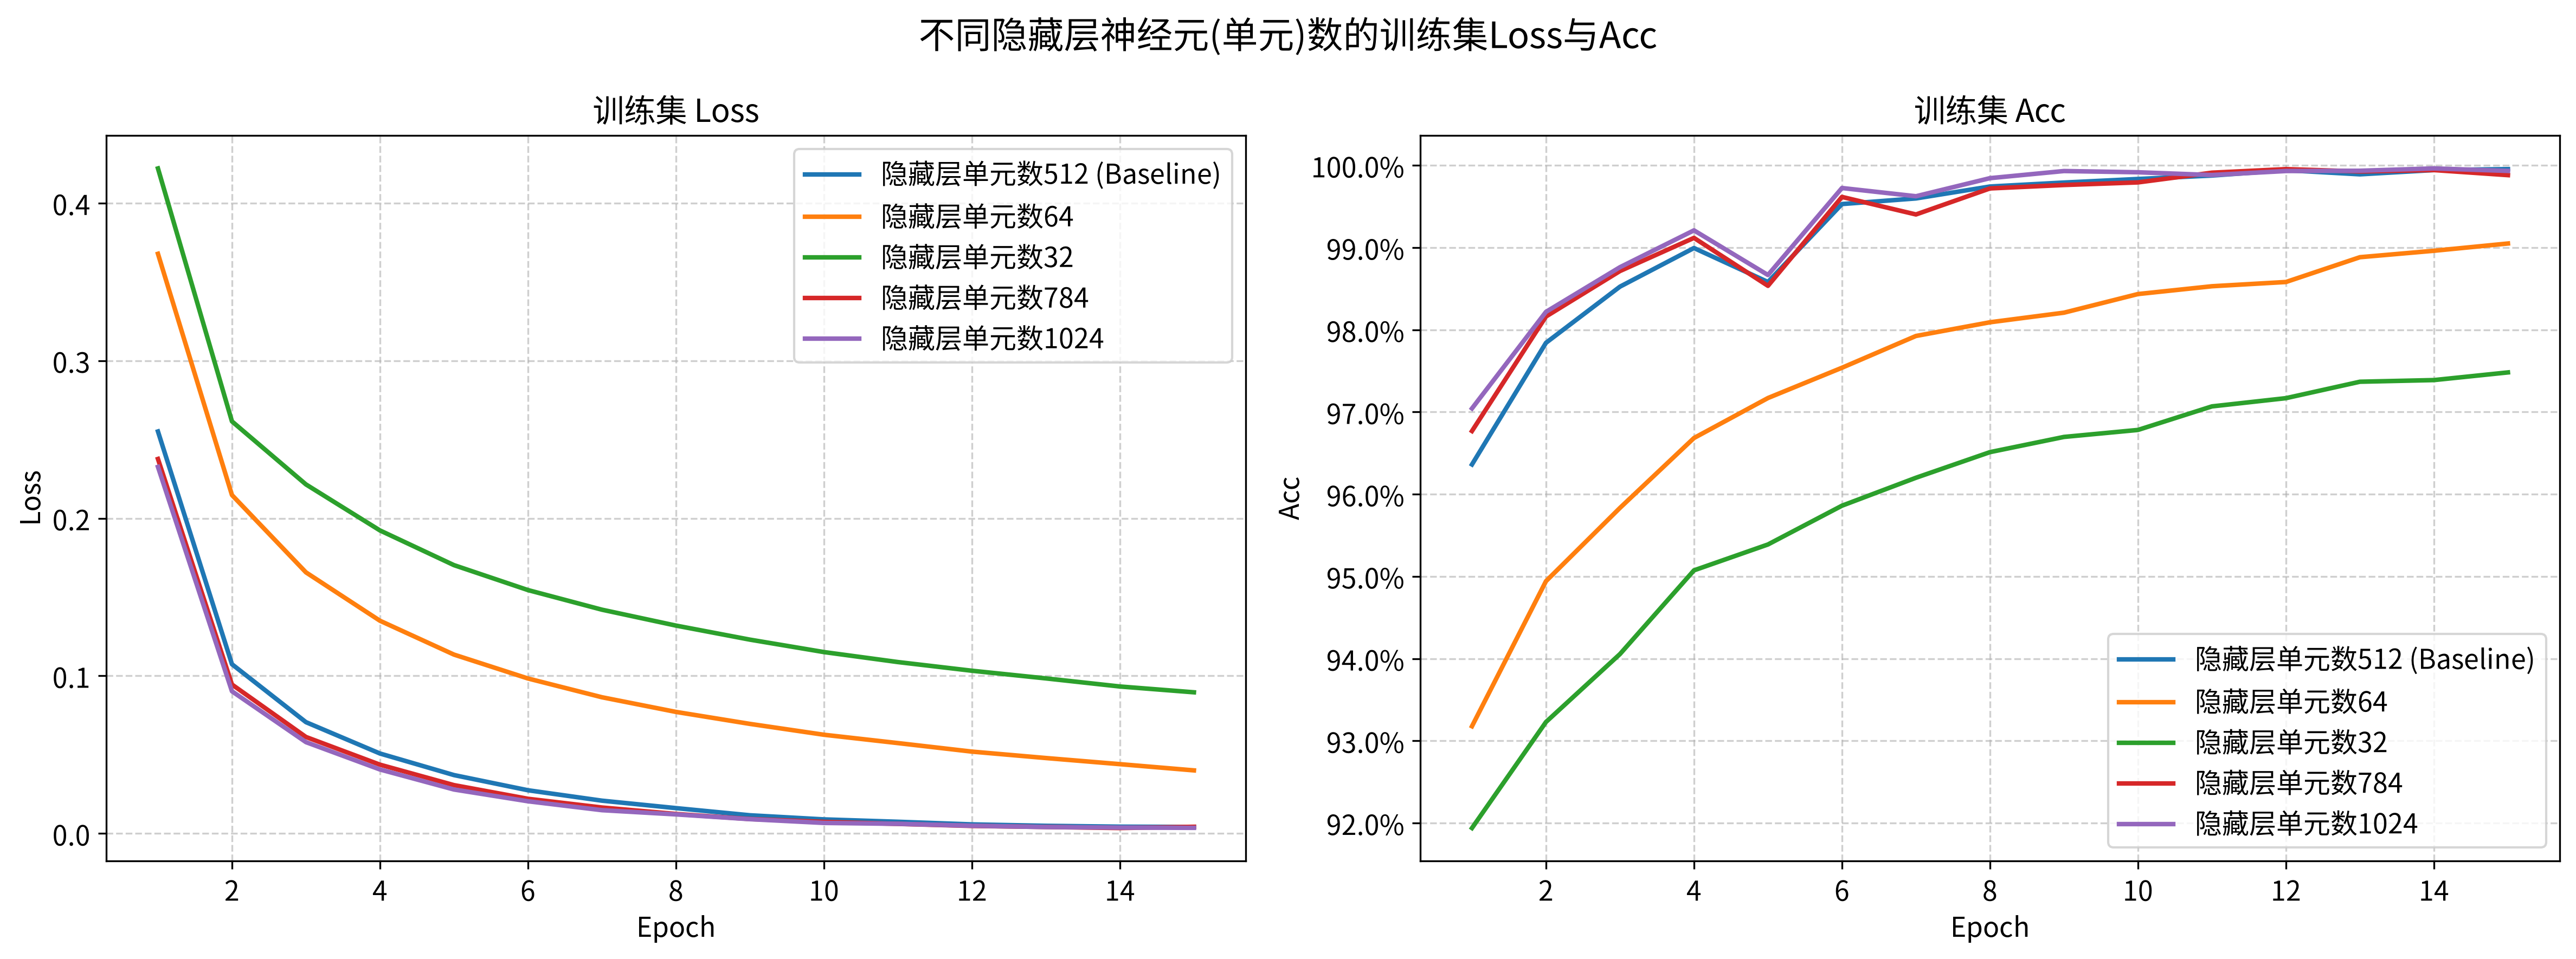

In [188]:
compare_data = {
    '隐藏层单元数512 (Baseline)': train_result_df,
    '隐藏层单元数64': train_result_df1,
    '隐藏层单元数32': train_result_df2,
    '隐藏层单元数784': train_result_df3,
    '隐藏层单元数1024': train_result_df4
}
plot_multiple_models_train_result(compare_data, title="不同隐藏层神经元(单元)数的训练集Loss与Acc")

测试集结果对比：

| | Baseline (512) | 64 | 32 | 784 | 1024 |
| :---: | :---: | :---: | :---: | :---: | :---: |
| Loss | 0.0742 | 0.0908 | 0.1267 | 0.0754 | 0.0749 |
| Acc | 98.20% | 97.38% | 96.30% | 98.25% | **98.42%** |

结论：适当增加隐藏层神经元个数，可以提高模型的预测能力。


##### 2.3 训练轮次epoch与批次大小batch
（1）调大epoch为25

In [189]:
model = Net() # 定义模型
criterion = nn.CrossEntropyLoss() # 损失函数（交叉熵损失）
optimizer = optim.RMSprop(model.parameters(), lr = 0.001) # 优化器

train_result_df1 = train_model(model, epochs=25, batch = 128) # 调大epoch为25
train_result_df1.style.format({'Acc': '{:.2%}'}).hide(axis = 'index')

Epoch,Loss,Acc
1/25,0.249517,96.46%
2/25,0.105732,97.88%
3/25,0.069774,98.56%
4/25,0.050239,99.05%
5/25,0.036653,98.85%
6/25,0.026831,99.55%
7/25,0.020508,99.65%
8/25,0.015431,99.80%
9/25,0.011221,99.70%
10/25,0.008790,99.90%


In [190]:
test_result_df1 = evaluate_model(model, batch=128)
test_result_df1.round(4)

测试集loss: 0.0878
测试集Acc: 98.20%  (9820/10000)


,Predict,Prob_0,Prob_1,Prob_2,Prob_3,Prob_4,Prob_5,Prob_6,Prob_7,Prob_8,Prob_9
0,7,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
1,2,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,1,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,4,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...
9995,2,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
9996,3,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
9997,4,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
9998,5,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0


（2）调小epoch为10

In [191]:
model = Net() # 定义模型
criterion = nn.CrossEntropyLoss() # 损失函数（交叉熵损失）
optimizer = optim.RMSprop(model.parameters(), lr = 0.001) # 优化器

train_result_df2 = train_model(model, epochs=10, batch = 128) # 调小epoch为10
train_result_df2.style.format({'Acc': '{:.2%}'}).hide(axis = 'index')

Epoch,Loss,Acc
1/10,0.253476,96.38%
2/10,0.107777,97.88%
3/10,0.071161,98.46%
4/10,0.051624,98.98%
5/10,0.037522,98.98%
6/10,0.028307,99.57%
7/10,0.021346,99.62%
8/10,0.016546,99.74%
9/10,0.012244,99.86%
10/10,0.009541,99.89%


In [192]:
test_result_df2 = evaluate_model(model, batch=128)
test_result_df2.round(4)

测试集loss: 0.0607
测试集Acc: 98.13%  (9813/10000)


,Predict,Prob_0,Prob_1,Prob_2,Prob_3,Prob_4,Prob_5,Prob_6,Prob_7,Prob_8,Prob_9
0,7,0.0,0.0000,0.0,0.0,0.0000,0.0,0.0,1.0,0.0,0.0000
1,2,0.0,0.0000,1.0,0.0,0.0000,0.0,0.0,0.0,0.0,0.0000
2,1,0.0,0.9999,0.0,0.0,0.0000,0.0,0.0,0.0,0.0,0.0000
3,0,1.0,0.0000,0.0,0.0,0.0000,0.0,0.0,0.0,0.0,0.0000
4,4,0.0,0.0000,0.0,0.0,0.9996,0.0,0.0,0.0,0.0,0.0004
...,...,...,...,...,...,...,...,...,...,...,...
9995,2,0.0,0.0000,1.0,0.0,0.0000,0.0,0.0,0.0,0.0,0.0000
9996,3,0.0,0.0000,0.0,1.0,0.0000,0.0,0.0,0.0,0.0,0.0000
9997,4,0.0,0.0000,0.0,0.0,1.0000,0.0,0.0,0.0,0.0,0.0000
9998,5,0.0,0.0000,0.0,0.0,0.0000,1.0,0.0,0.0,0.0,0.0000


（3）调大batch为512

In [193]:
model = Net() # 定义模型
criterion = nn.CrossEntropyLoss() # 损失函数（交叉熵损失）
optimizer = optim.RMSprop(model.parameters(), lr = 0.001) # 优化器

train_result_df3 = train_model(model, epochs=15, batch = 512) # 调大batch为512
train_result_df3.style.format({'Acc': '{:.2%}'}).hide(axis = 'index')

Epoch,Loss,Acc
1/15,0.389039,93.97%
2/15,0.173561,94.92%
3/15,0.127240,96.13%
4/15,0.097256,97.13%
5/15,0.078514,94.39%
6/15,0.064305,97.86%
7/15,0.052740,98.34%
8/15,0.043932,97.89%
9/15,0.035914,99.19%
10/15,0.030351,99.01%


In [194]:
test_result_df3 = evaluate_model(model, batch=512)
test_result_df3.round(4)

测试集loss: 0.0915
测试集Acc: 97.37%  (9737/10000)


,Predict,Prob_0,Prob_1,Prob_2,Prob_3,Prob_4,Prob_5,Prob_6,Prob_7,Prob_8,Prob_9
0,7,0.0,0.0000,0.0000,0.0000,0.0000,0.0000,0.0,1.0000,0.0000,0.0000
1,2,0.0,0.0000,1.0000,0.0000,0.0000,0.0000,0.0,0.0000,0.0000,0.0000
2,1,0.0,0.9997,0.0001,0.0000,0.0000,0.0000,0.0,0.0001,0.0001,0.0000
3,0,1.0,0.0000,0.0000,0.0000,0.0000,0.0000,0.0,0.0000,0.0000,0.0000
4,4,0.0,0.0000,0.0000,0.0000,0.9962,0.0000,0.0,0.0000,0.0000,0.0038
...,...,...,...,...,...,...,...,...,...,...,...
9995,2,0.0,0.0000,1.0000,0.0000,0.0000,0.0000,0.0,0.0000,0.0000,0.0000
9996,3,0.0,0.0000,0.0000,0.9997,0.0000,0.0001,0.0,0.0000,0.0000,0.0002
9997,4,0.0,0.0000,0.0000,0.0000,1.0000,0.0000,0.0,0.0000,0.0000,0.0000
9998,5,0.0,0.0000,0.0000,0.0000,0.0000,1.0000,0.0,0.0000,0.0000,0.0000


（4）调小batch为32

In [195]:
model = Net() # 定义模型
criterion = nn.CrossEntropyLoss() # 损失函数（交叉熵损失）
optimizer = optim.RMSprop(model.parameters(), lr = 0.001) # 优化器

train_result_df4 = train_model(model, epochs=15, batch = 32) # 调小batch为32
train_result_df4.style.format({'Acc': '{:.2%}'}).hide(axis = 'index')

Epoch,Loss,Acc
1/15,0.193620,97.37%
2/15,0.079788,98.52%
3/15,0.051874,98.78%
4/15,0.038057,99.19%
5/15,0.027297,99.27%
6/15,0.020756,99.56%
7/15,0.016765,99.69%
8/15,0.012688,99.81%
9/15,0.009852,99.77%
10/15,0.009007,99.85%


In [196]:
test_result_df4 = evaluate_model(model, batch=32)
test_result_df4.round(4)

测试集loss: 0.1043
测试集Acc: 98.24%  (9824/10000)


,Predict,Prob_0,Prob_1,Prob_2,Prob_3,Prob_4,Prob_5,Prob_6,Prob_7,Prob_8,Prob_9
0,7,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
1,2,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,1,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,4,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...
9995,2,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
9996,3,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
9997,4,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
9998,5,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0


（5）对比结果可视化

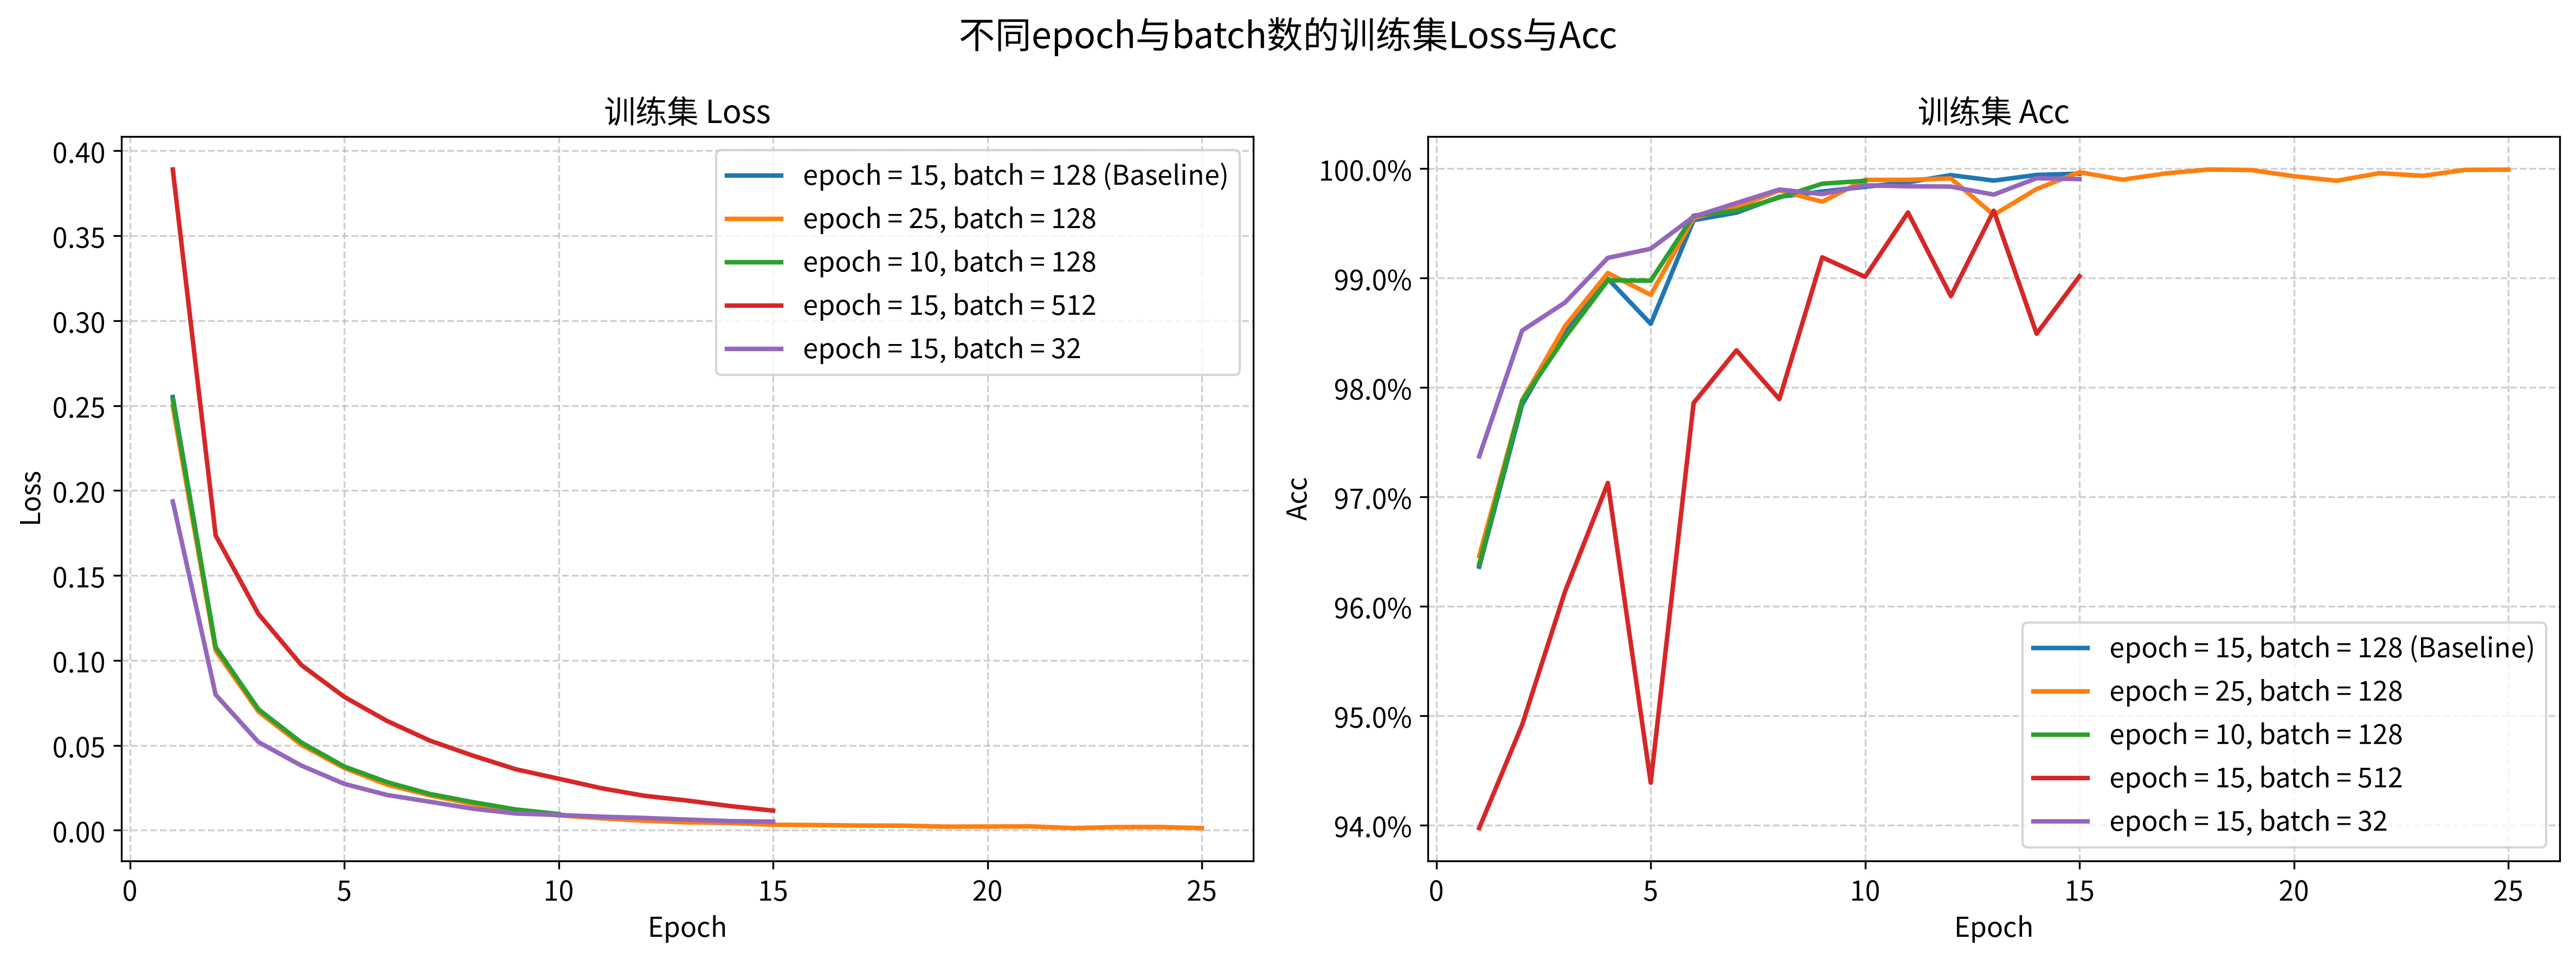

In [197]:
compare_data = {
    'epoch = 15, batch = 128 (Baseline)': train_result_df,
    'epoch = 25, batch = 128': train_result_df1,
    'epoch = 10, batch = 128': train_result_df2,
    'epoch = 15, batch = 512': train_result_df3,
    'epoch = 15, batch = 32': train_result_df4
}
plot_multiple_models_train_result(compare_data, title="不同epoch与batch数的训练集Loss与Acc")

测试集结果对比：

| | Baseline (epoch=15, batch=128) | epoch=25, batch=128 | epoch=10, batch=128 | epoch=15, batch=512 | epoch=15, batch=32 |
| :---: | :---: | :---: | :---: | :---: | :---: |
| Loss | 0.0742 | 0.0878 | 0.0607 | 0.0915 | 0.1043 |
| Acc | 98.20% | 98.20% | 98.13% | 97.37% | **98.24%** |

结论：训练epoch过大可能导致过拟合；训练epoch过小可能使训练不充分；batch太大，每次梯度下降参考的样本越多（或梯度下降总次数变少），可能使模型陷入局部最优，从而在测试集上的表现欠佳。


##### 2.4 调整Dropout失活比例
（1）定义可调整失活比例的网络结构

In [198]:
# 可调整Dropout失活比例的网络结构
class DropoutNet(nn.Module):
    def __init__(self, dropout):
        super().__init__()
        self.fc1 = nn.Linear(784, 512) # 输入层 784 -> 隐藏层 512
        self.out = nn.Linear(512, 10) # 隐藏层 512 -> 输出层 10
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(p=dropout) # 随机丢弃p比例数量的神经元

    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.dropout(x)  # 在激活函数之后，输出层之前，应用Dropout
        x = self.out(x)  # 直接输出线性结果
        return x

（2）设置Dropout比例为0.2

In [199]:
model = DropoutNet(0.2) # 定义Dropout比例为0.2的模型
criterion = nn.CrossEntropyLoss() # 损失函数（交叉熵损失）
optimizer = optim.RMSprop(model.parameters(), lr = 0.001) # 优化器

train_result_df1 = train_model(model, epochs=15, batch = 128)
train_result_df1.style.format({'Acc': '{:.2%}'}).hide(axis = 'index')

Epoch,Loss,Acc
1/15,0.265895,96.17%
2/15,0.119821,97.82%
3/15,0.083032,98.22%
4/15,0.063297,98.87%
5/15,0.049906,99.05%
6/15,0.040447,99.32%
7/15,0.032372,99.46%
8/15,0.027138,99.64%
9/15,0.024263,99.73%
10/15,0.018955,99.78%


In [200]:
test_result_df1 = evaluate_model(model, batch=128)
test_result_df1.round(4)

测试集loss: 0.0702
测试集Acc: 98.17%  (9817/10000)


,Predict,Prob_0,Prob_1,Prob_2,Prob_3,Prob_4,Prob_5,Prob_6,Prob_7,Prob_8,Prob_9
0,7,0.0,0.0,0.0,0.0,0.0000,0.0,0.0,1.0,0.0,0.0000
1,2,0.0,0.0,1.0,0.0,0.0000,0.0,0.0,0.0,0.0,0.0000
2,1,0.0,1.0,0.0,0.0,0.0000,0.0,0.0,0.0,0.0,0.0000
3,0,1.0,0.0,0.0,0.0,0.0000,0.0,0.0,0.0,0.0,0.0000
4,4,0.0,0.0,0.0,0.0,0.9963,0.0,0.0,0.0,0.0,0.0037
...,...,...,...,...,...,...,...,...,...,...,...
9995,2,0.0,0.0,1.0,0.0,0.0000,0.0,0.0,0.0,0.0,0.0000
9996,3,0.0,0.0,0.0,1.0,0.0000,0.0,0.0,0.0,0.0,0.0000
9997,4,0.0,0.0,0.0,0.0,1.0000,0.0,0.0,0.0,0.0,0.0000
9998,5,0.0,0.0,0.0,0.0,0.0000,1.0,0.0,0.0,0.0,0.0000


（3）设置Dropout比例为0.5

In [201]:
model = DropoutNet(0.5) # 定义Dropout比例为0.5的模型
criterion = nn.CrossEntropyLoss() # 损失函数（交叉熵损失）
optimizer = optim.RMSprop(model.parameters(), lr = 0.001) # 优化器

train_result_df2 = train_model(model, epochs=15, batch = 128)
train_result_df2.style.format({'Acc': '{:.2%}'}).hide(axis = 'index')

Epoch,Loss,Acc
1/15,0.306699,95.63%
2/15,0.155855,97.27%
3/15,0.116841,97.90%
4/15,0.096161,98.46%
5/15,0.081611,98.64%
6/15,0.073134,98.95%
7/15,0.064713,99.12%
8/15,0.057236,99.21%
9/15,0.052956,99.35%
10/15,0.051098,99.44%


In [202]:
test_result_df2 = evaluate_model(model, batch=128)
test_result_df2.round(4)

测试集loss: 0.0588
测试集Acc: 98.40%  (9840/10000)


,Predict,Prob_0,Prob_1,Prob_2,Prob_3,Prob_4,Prob_5,Prob_6,Prob_7,Prob_8,Prob_9
0,7,0.0,0.0000,0.0,0.0,0.0000,0.0,0.0,1.0000,0.0,0.0000
1,2,0.0,0.0000,1.0,0.0,0.0000,0.0,0.0,0.0000,0.0,0.0000
2,1,0.0,0.9998,0.0,0.0,0.0000,0.0,0.0,0.0001,0.0,0.0000
3,0,1.0,0.0000,0.0,0.0,0.0000,0.0,0.0,0.0000,0.0,0.0000
4,4,0.0,0.0000,0.0,0.0,0.9968,0.0,0.0,0.0000,0.0,0.0032
...,...,...,...,...,...,...,...,...,...,...,...
9995,2,0.0,0.0000,1.0,0.0,0.0000,0.0,0.0,0.0000,0.0,0.0000
9996,3,0.0,0.0000,0.0,1.0,0.0000,0.0,0.0,0.0000,0.0,0.0000
9997,4,0.0,0.0000,0.0,0.0,1.0000,0.0,0.0,0.0000,0.0,0.0000
9998,5,0.0,0.0000,0.0,0.0,0.0000,1.0,0.0,0.0000,0.0,0.0000


（4）设置Dropout比例为0.7

In [203]:
model = DropoutNet(0.7) # 定义Dropout比例为0.7的模型
criterion = nn.CrossEntropyLoss() # 损失函数（交叉熵损失）
optimizer = optim.RMSprop(model.parameters(), lr = 0.001) # 优化器

train_result_df3 = train_model(model, epochs=15, batch = 128)
train_result_df3.style.format({'Acc': '{:.2%}'}).hide(axis = 'index')

Epoch,Loss,Acc
1/15,0.364441,94.89%
2/15,0.208600,96.52%
3/15,0.167155,97.15%
4/15,0.143495,97.75%
5/15,0.130661,97.98%
6/15,0.120813,98.21%
7/15,0.113929,98.44%
8/15,0.108433,98.59%
9/15,0.103198,98.73%
10/15,0.096455,98.84%


In [204]:
test_result_df3 = evaluate_model(model, batch=128)
test_result_df3.round(4)

测试集loss: 0.0675
测试集Acc: 98.13%  (9813/10000)


,Predict,Prob_0,Prob_1,Prob_2,Prob_3,Prob_4,Prob_5,Prob_6,Prob_7,Prob_8,Prob_9
0,7,0.0000,0.0000,0.0000,0.0000,0.000,0.0000,0.0,1.0000,0.0,0.0000
1,2,0.0000,0.0000,1.0000,0.0000,0.000,0.0000,0.0,0.0000,0.0,0.0000
2,1,0.0000,0.9999,0.0000,0.0000,0.000,0.0000,0.0,0.0001,0.0,0.0000
3,0,0.9999,0.0000,0.0001,0.0000,0.000,0.0000,0.0,0.0000,0.0,0.0000
4,4,0.0000,0.0000,0.0000,0.0000,0.993,0.0000,0.0,0.0000,0.0,0.0069
...,...,...,...,...,...,...,...,...,...,...,...
9995,2,0.0000,0.0000,1.0000,0.0000,0.000,0.0000,0.0,0.0000,0.0,0.0000
9996,3,0.0000,0.0000,0.0000,0.9999,0.000,0.0001,0.0,0.0000,0.0,0.0000
9997,4,0.0000,0.0000,0.0000,0.0000,1.000,0.0000,0.0,0.0000,0.0,0.0000
9998,5,0.0000,0.0000,0.0000,0.0000,0.000,1.0000,0.0,0.0000,0.0,0.0000


（5）对比结果可视化

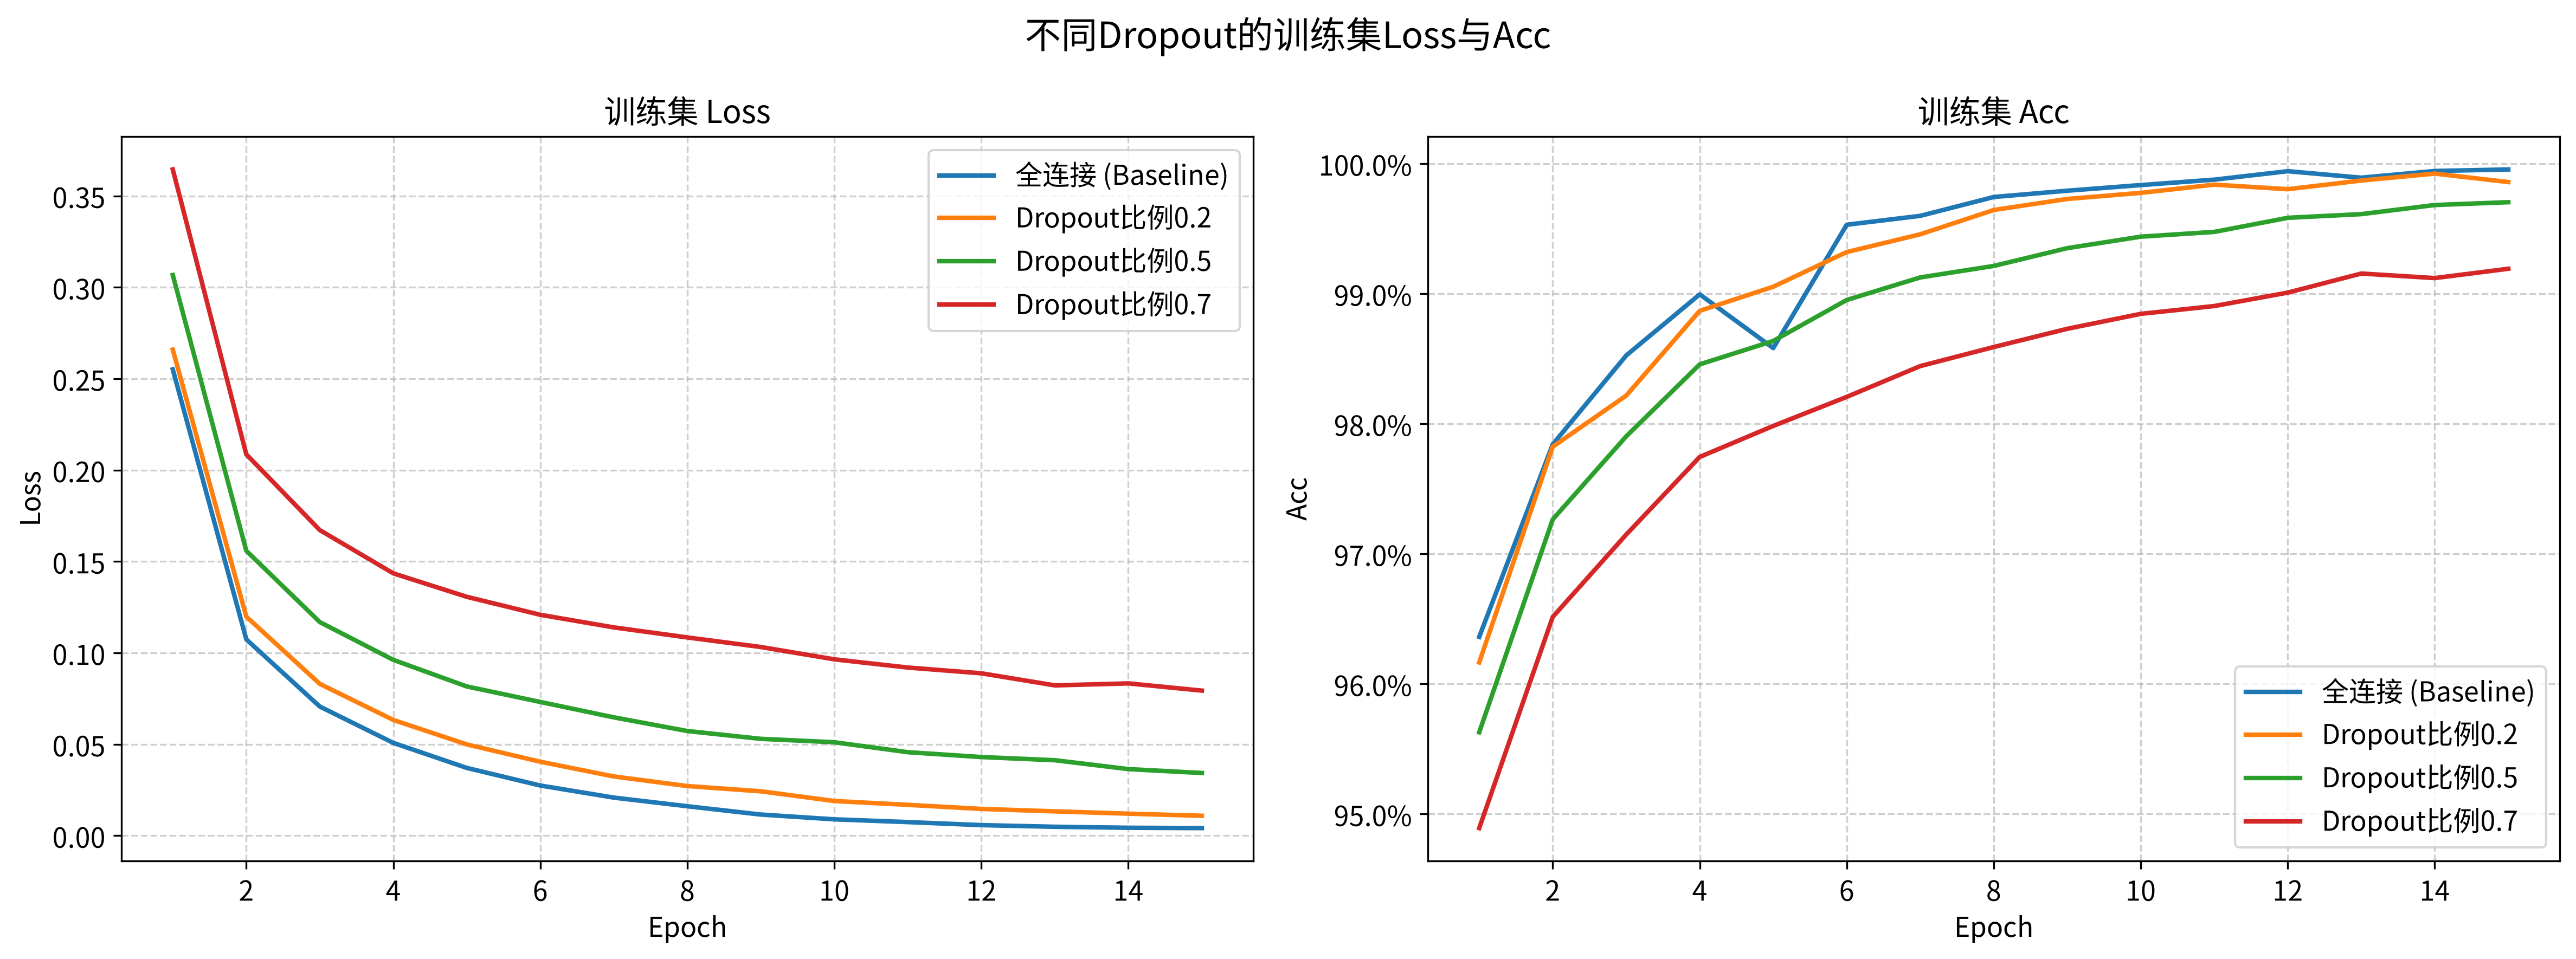

In [205]:
compare_data = {
    '全连接 (Baseline)': train_result_df,
    'Dropout比例0.2': train_result_df1,
    'Dropout比例0.5': train_result_df2,
    'Dropout比例0.7': train_result_df3
}
plot_multiple_models_train_result(compare_data, title="不同Dropout的训练集Loss与Acc")

测试集结果对比：

| | Baseline (Dropout=0) | Dropout=0.2 | Dropout=0.5 | Dropout=0.7 |
| :---: | :---: | :---: | :---: | :---: |
| Loss | 0.0742 | 0.0702 | **0.0588** | 0.0675 |
| Acc | 98.20% | 98.17% | **98.40%** | 98.13% |

结论：适当失活隐藏层神经元，可以提高模型的泛化能力，但是失活比例过高也会导致模型学习不充分。


##### 2.5 将loss函数改为MSE
（1）修改训练与评估函数，使训练时使用one-hot编码，适配MSE的loss函数

In [206]:
import torch.nn.functional as F # 将无序类别标签转为one-hot

def train_model_mse(model, epochs, batch):
    # 将模型迁移到GPU训练
    model = model.to(device)
    
    # 全数据集分 batch
    g = torch.Generator()
    g.manual_seed(42)  # 固定随机种子，保证 batch 划分可复现

    train_dataset = TensorDataset(x_train_tensor, y_train_tensor)
    train_dataloader = DataLoader(
        train_dataset, batch_size=batch, shuffle=True, generator=g
    )

    eval_dataloader = DataLoader(
        train_dataset, batch_size=batch, shuffle=False
    )

    loss_result = []

    for epoch in range(epochs):
        train_total_loss_sum = 0.0
        train_num = 0

        model.train()
        for batch_x, batch_y in train_dataloader:
            optimizer.zero_grad()
            preds_y = model(batch_x)

            # 把整数标签 (B,) 转成 one-hot (B,10) 再算 loss
            batch_y_one_hot = F.one_hot(batch_y, num_classes=10).float()
            loss_train = criterion(preds_y, batch_y_one_hot)

            loss_train.backward()
            optimizer.step()

            train_total_loss_sum += loss_train.item() * batch_y.size(0)
            train_num += batch_y.size(0)

        train_correct = 0
        eval_num = 0

        model.eval()
        with torch.no_grad():
            for batch_x, batch_y in eval_dataloader:
                train_preds = model(batch_x)
                predicted_classes = torch.argmax(train_preds, dim=1)
                train_correct += (predicted_classes == batch_y).sum().item()
                eval_num += batch_y.size(0)

        loss_result.append([
            f"{epoch + 1}/{epochs}",
            train_total_loss_sum / train_num,
            train_correct / eval_num
        ])

    result_df = pd.DataFrame(loss_result, columns=['Epoch', 'Loss', 'Acc'])
    return result_df

# 评估函数
def evaluate_model_mse(model, batch):
    model.eval()  # 切换到测试状态

    test_correct = 0
    test_num = 0
    test_total_loss_sum = 0.0

    test_result = []
    test_probs = []

    test_dataset = TensorDataset(x_test_tensor, y_test_tensor)
    test_dataloader = DataLoader(test_dataset, batch_size=batch, shuffle=False)

    with torch.no_grad():
        for batch_x, batch_y in test_dataloader:
            test_preds = model(batch_x)

            # 标签转 one-hot 后再算 MSE
            batch_y_one_hot = F.one_hot(batch_y, num_classes=10).float()
            loss = criterion(test_preds, batch_y_one_hot)

            test_total_loss_sum += loss.item() * batch_y.size(0)
            test_num += batch_y.size(0)

            predicted_classes = torch.argmax(test_preds, dim=1)
            test_correct += (predicted_classes == batch_y).sum().item()

            test_result += predicted_classes.tolist()
            test_probs += torch.softmax(test_preds, dim=1).tolist()

    avg_test_loss = test_total_loss_sum / test_num
    accuracy = test_correct / test_num

    print(f"测试集loss: {avg_test_loss:.4f}")
    print(f"测试集Acc: {accuracy * 100:.2f}%  ({test_correct}/{test_num})")

    result_df = pd.DataFrame(test_result, columns=['Predict'])
    prob_columns = [f'Prob_{i}' for i in range(10)]
    prob_df = pd.DataFrame(test_probs, columns=prob_columns)
    result_df = pd.concat([result_df, prob_df], axis=1)

    return result_df

（2）修改loss函数为MSE

In [207]:
model = Net() # 定义 激活函数为tanh 的模型
criterion = nn.MSELoss() # 损失函数（MSE）
optimizer = optim.RMSprop(model.parameters(), lr = 0.001) # 优化器

train_result_df1 = train_model_mse(model, epochs=15, batch = 128)
train_result_df1.style.format({'Acc': '{:.2%}'}).hide(axis = 'index')

Epoch,Loss,Acc
1/15,0.038668,95.18%
2/15,0.012658,96.72%
3/15,0.010178,97.67%
4/15,0.008414,98.21%
5/15,0.007339,98.59%
6/15,0.006578,98.86%
7/15,0.006020,99.01%
8/15,0.005615,99.18%
9/15,0.005276,99.30%
10/15,0.004978,99.38%


In [208]:
test_result_df1 = evaluate_model_mse(model, batch=128)
test_result_df1.round(4)

测试集loss: 0.0068
测试集Acc: 98.13%  (9813/10000)


,Predict,Prob_0,Prob_1,Prob_2,Prob_3,Prob_4,Prob_5,Prob_6,Prob_7,Prob_8,Prob_9
0,7,0.0863,0.0862,0.0863,0.0856,0.0857,0.0859,0.0864,0.2243,0.0874,0.0859
1,2,0.0832,0.0862,0.2093,0.0836,0.0877,0.0899,0.0829,0.0879,0.1031,0.0863
2,1,0.0848,0.2346,0.0860,0.0849,0.0838,0.0843,0.0851,0.0834,0.0899,0.0832
3,0,0.2700,0.0831,0.0820,0.0841,0.0817,0.0804,0.0813,0.0808,0.0761,0.0805
4,4,0.0886,0.0867,0.0853,0.0866,0.2263,0.0849,0.0845,0.0880,0.0888,0.0804
...,...,...,...,...,...,...,...,...,...,...,...
9995,2,0.0823,0.0859,0.2308,0.0860,0.0852,0.0847,0.0834,0.0857,0.0923,0.0838
9996,3,0.0846,0.0842,0.0804,0.2497,0.0833,0.0835,0.0847,0.0837,0.0810,0.0849
9997,4,0.0894,0.0865,0.0852,0.0857,0.2342,0.0856,0.0862,0.0834,0.0904,0.0735
9998,5,0.0819,0.0841,0.0762,0.0859,0.0843,0.2402,0.0805,0.0864,0.0968,0.0837


（3）对比结果可视化

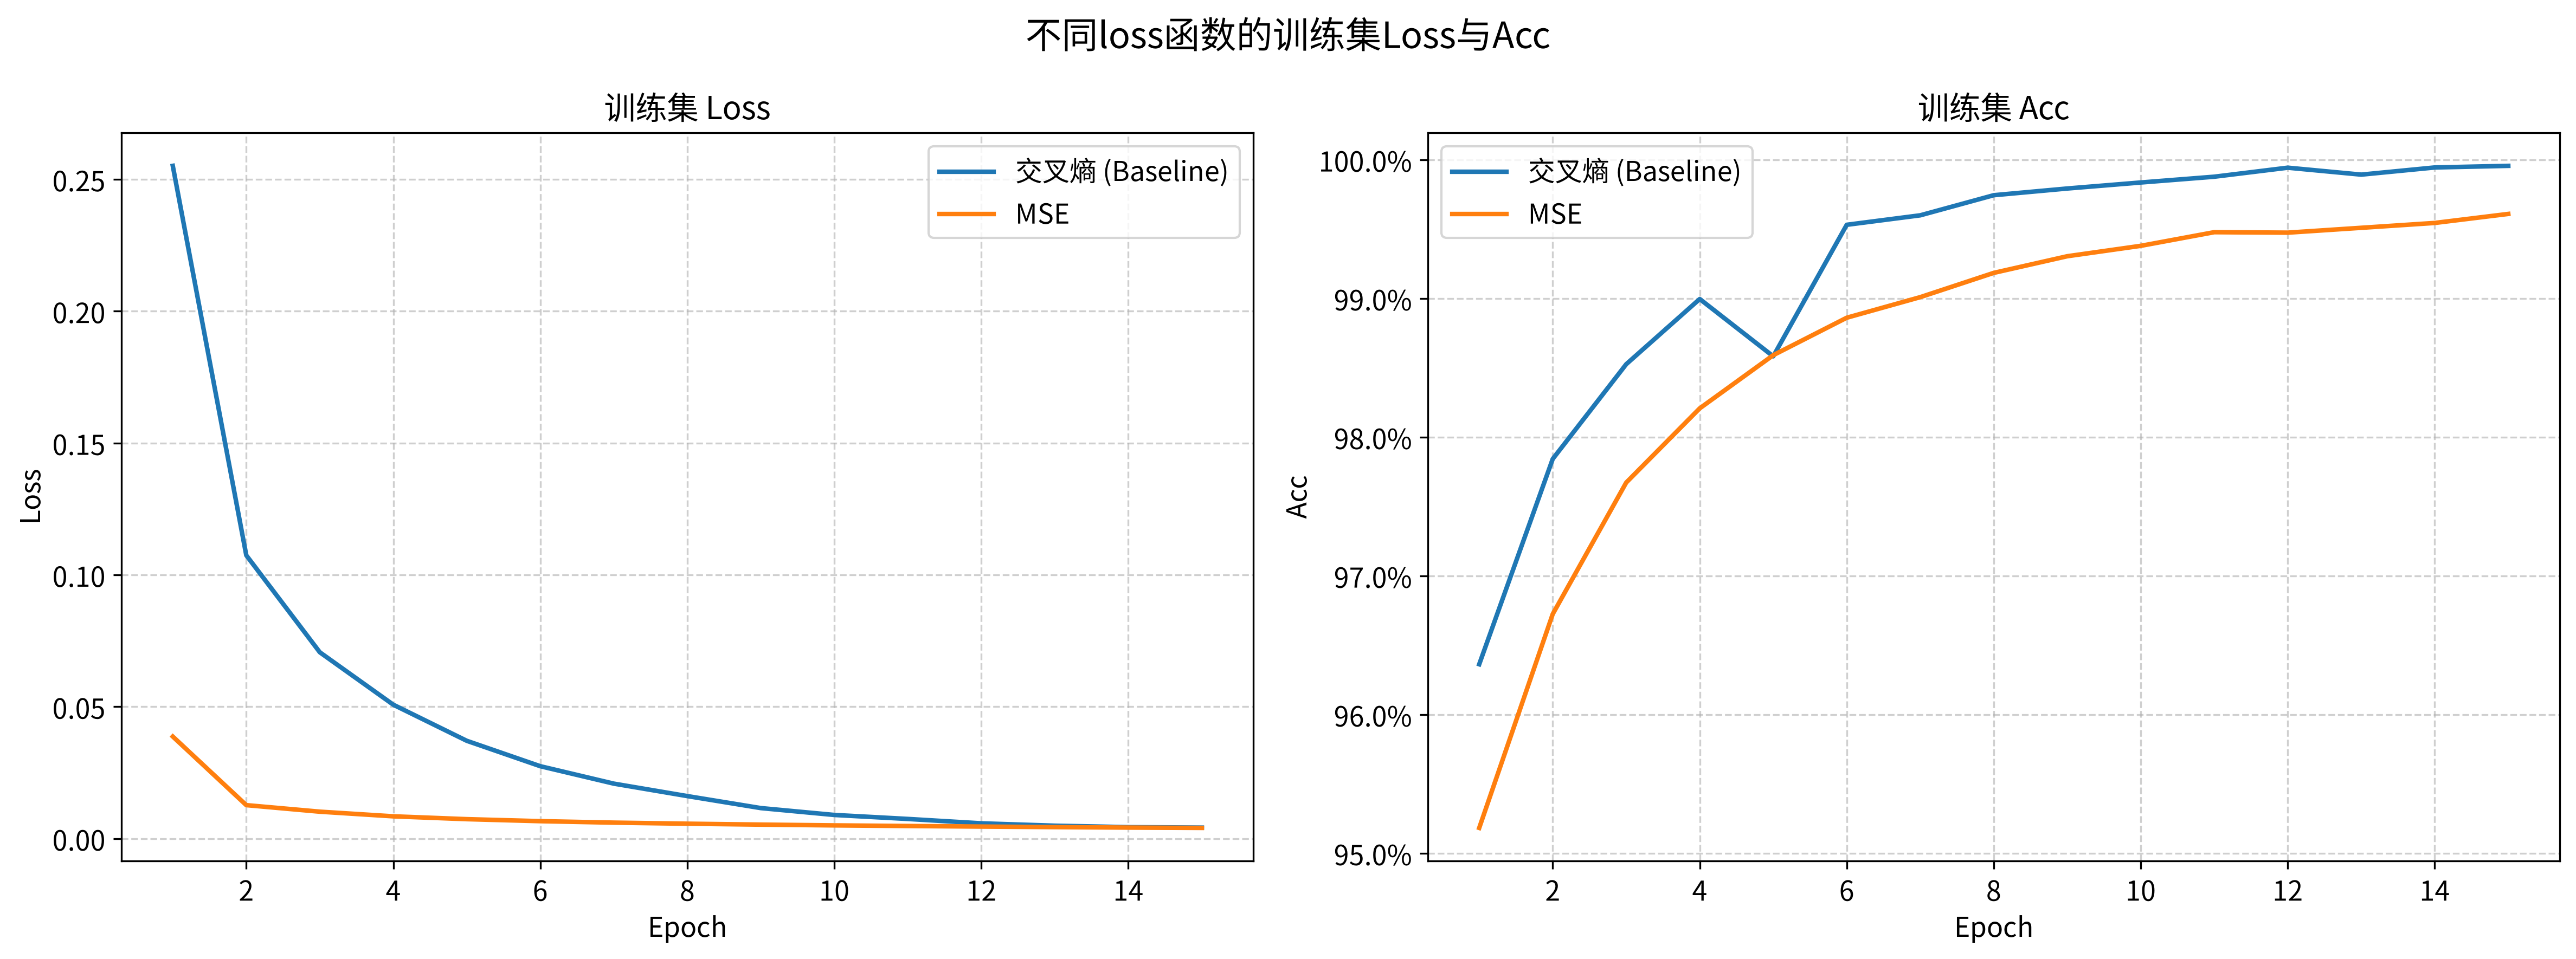

In [209]:
compare_data = {
    '交叉熵 (Baseline)': train_result_df,
    'MSE': train_result_df1
}
plot_multiple_models_train_result(compare_data, title="不同loss函数的训练集Loss与Acc")

测试集结果对比：

| | Baseline (CrossEntropy) | MSE |
| :---: | :---: | :---: |
| Loss | 0.0742 | 0.0068 |
| Acc | **98.20%** | 98.13% |

结论：交叉熵的收敛速度更快，最终Acc上限更高，在分类任务上优于MSE.


##### 2.6 激活函数改为tanh
（1）调整网络结构，将激活函数修改为tanh，训练并评估模型

In [210]:
# 修改网络结构，将激活函数调整为tanh
class TanhNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(784, 512) # 输入层 784 -> 隐藏层 512
        self.out = nn.Linear(512, 10) # 隐藏层 512 -> 输出层 10
        self.tanh = nn.Tanh()

    def forward(self, x):
        x = self.tanh(self.fc1(x))
        x = self.out(x)  # 直接输出线性结果
        return x

In [211]:
model = TanhNet() # 定义 激活函数为tanh 的模型
criterion = nn.CrossEntropyLoss() # 损失函数（交叉熵损失）
optimizer = optim.RMSprop(model.parameters(), lr = 0.001) # 优化器

train_result_df1 = train_model(model, epochs=15, batch = 128)
train_result_df1.style.format({'Acc': '{:.2%}'}).hide(axis = 'index')

Epoch,Loss,Acc
1/15,0.313827,94.36%
2/15,0.167554,96.28%
3/15,0.112813,97.36%
4/15,0.081616,98.19%
5/15,0.061645,98.24%
6/15,0.046334,99.10%
7/15,0.035231,99.27%
8/15,0.027030,99.44%
9/15,0.020098,99.67%
10/15,0.015157,99.70%


In [212]:
test_result_df1 = evaluate_model(model, batch=128)
test_result_df1.round(4)

测试集loss: 0.0747
测试集Acc: 98.03%  (9803/10000)


,Predict,Prob_0,Prob_1,Prob_2,Prob_3,Prob_4,Prob_5,Prob_6,Prob_7,Prob_8,Prob_9
0,7,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
1,2,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,1,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,4,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...
9995,2,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
9996,3,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
9997,4,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
9998,5,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0


（2）对比结果可视化

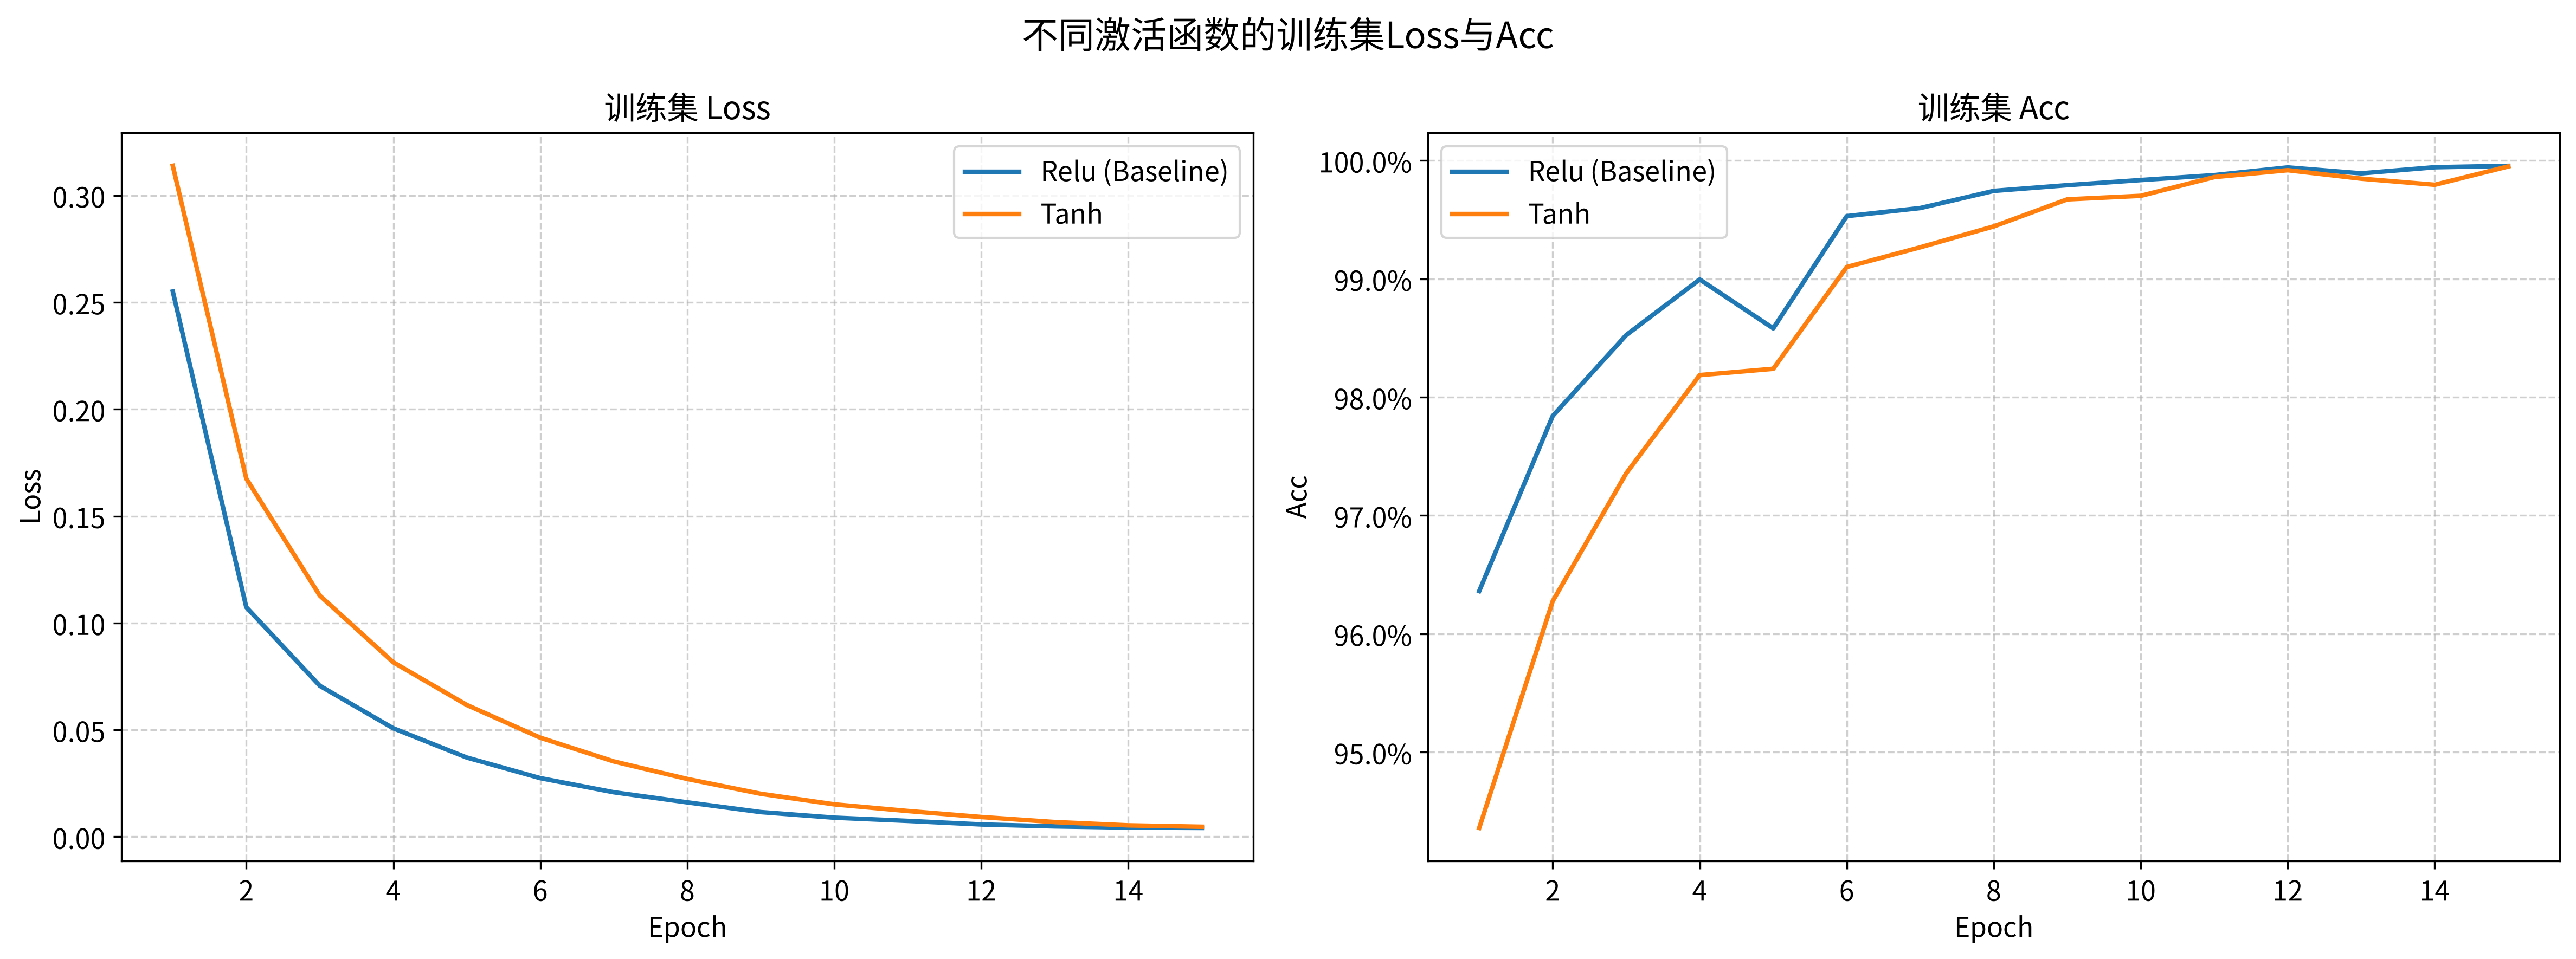

In [213]:
compare_data = {
    'Relu (Baseline)': train_result_df,
    'Tanh': train_result_df1
}
plot_multiple_models_train_result(compare_data, title="不同激活函数的训练集Loss与Acc")

测试集结果对比：

| | Baseline (ReLU) | Tanh |
| :---: | :---: | :---: |
| Loss | 0.0742 | 0.0747 |
| Acc | **98.20%** | 98.03% |

结论：ReLU的收敛速度更快，预测效果优于Tanh.


##### 2.7 将优化器改为Adam
（1）将优化器调整为Adam后，训练并评估模型

In [214]:
model = Net() # 定义模型
criterion = nn.CrossEntropyLoss() # 损失函数（交叉熵损失）
optimizer = optim.Adam(model.parameters(), lr = 0.001) # 调整为Adam优化器

train_result_df1 = train_model(model, epochs=15, batch = 128)
train_result_df1.style.format({'Acc': '{:.2%}'}).hide(axis = 'index')

Epoch,Loss,Acc
1/15,0.314273,95.62%
2/15,0.127334,97.39%
3/15,0.084427,98.14%
4/15,0.059300,98.60%
5/15,0.043979,99.04%
6/15,0.034337,99.42%
7/15,0.026069,99.21%
8/15,0.020004,99.76%
9/15,0.013772,99.79%
10/15,0.011413,99.85%


In [215]:
test_result_df1 = evaluate_model(model, batch=128)
test_result_df1.round(4)

测试集loss: 0.0682
测试集Acc: 98.10%  (9810/10000)


,Predict,Prob_0,Prob_1,Prob_2,Prob_3,Prob_4,Prob_5,Prob_6,Prob_7,Prob_8,Prob_9
0,7,0.0,0.0,0.0,0.0001,0.0,0.0,0.0,0.9999,0.0,0.0
1,2,0.0,0.0,1.0,0.0000,0.0,0.0,0.0,0.0000,0.0,0.0
2,1,0.0,1.0,0.0,0.0000,0.0,0.0,0.0,0.0000,0.0,0.0
3,0,1.0,0.0,0.0,0.0000,0.0,0.0,0.0,0.0000,0.0,0.0
4,4,0.0,0.0,0.0,0.0000,1.0,0.0,0.0,0.0000,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...
9995,2,0.0,0.0,1.0,0.0000,0.0,0.0,0.0,0.0000,0.0,0.0
9996,3,0.0,0.0,0.0,1.0000,0.0,0.0,0.0,0.0000,0.0,0.0
9997,4,0.0,0.0,0.0,0.0000,1.0,0.0,0.0,0.0000,0.0,0.0
9998,5,0.0,0.0,0.0,0.0000,0.0,1.0,0.0,0.0000,0.0,0.0


（2）对比结果可视化

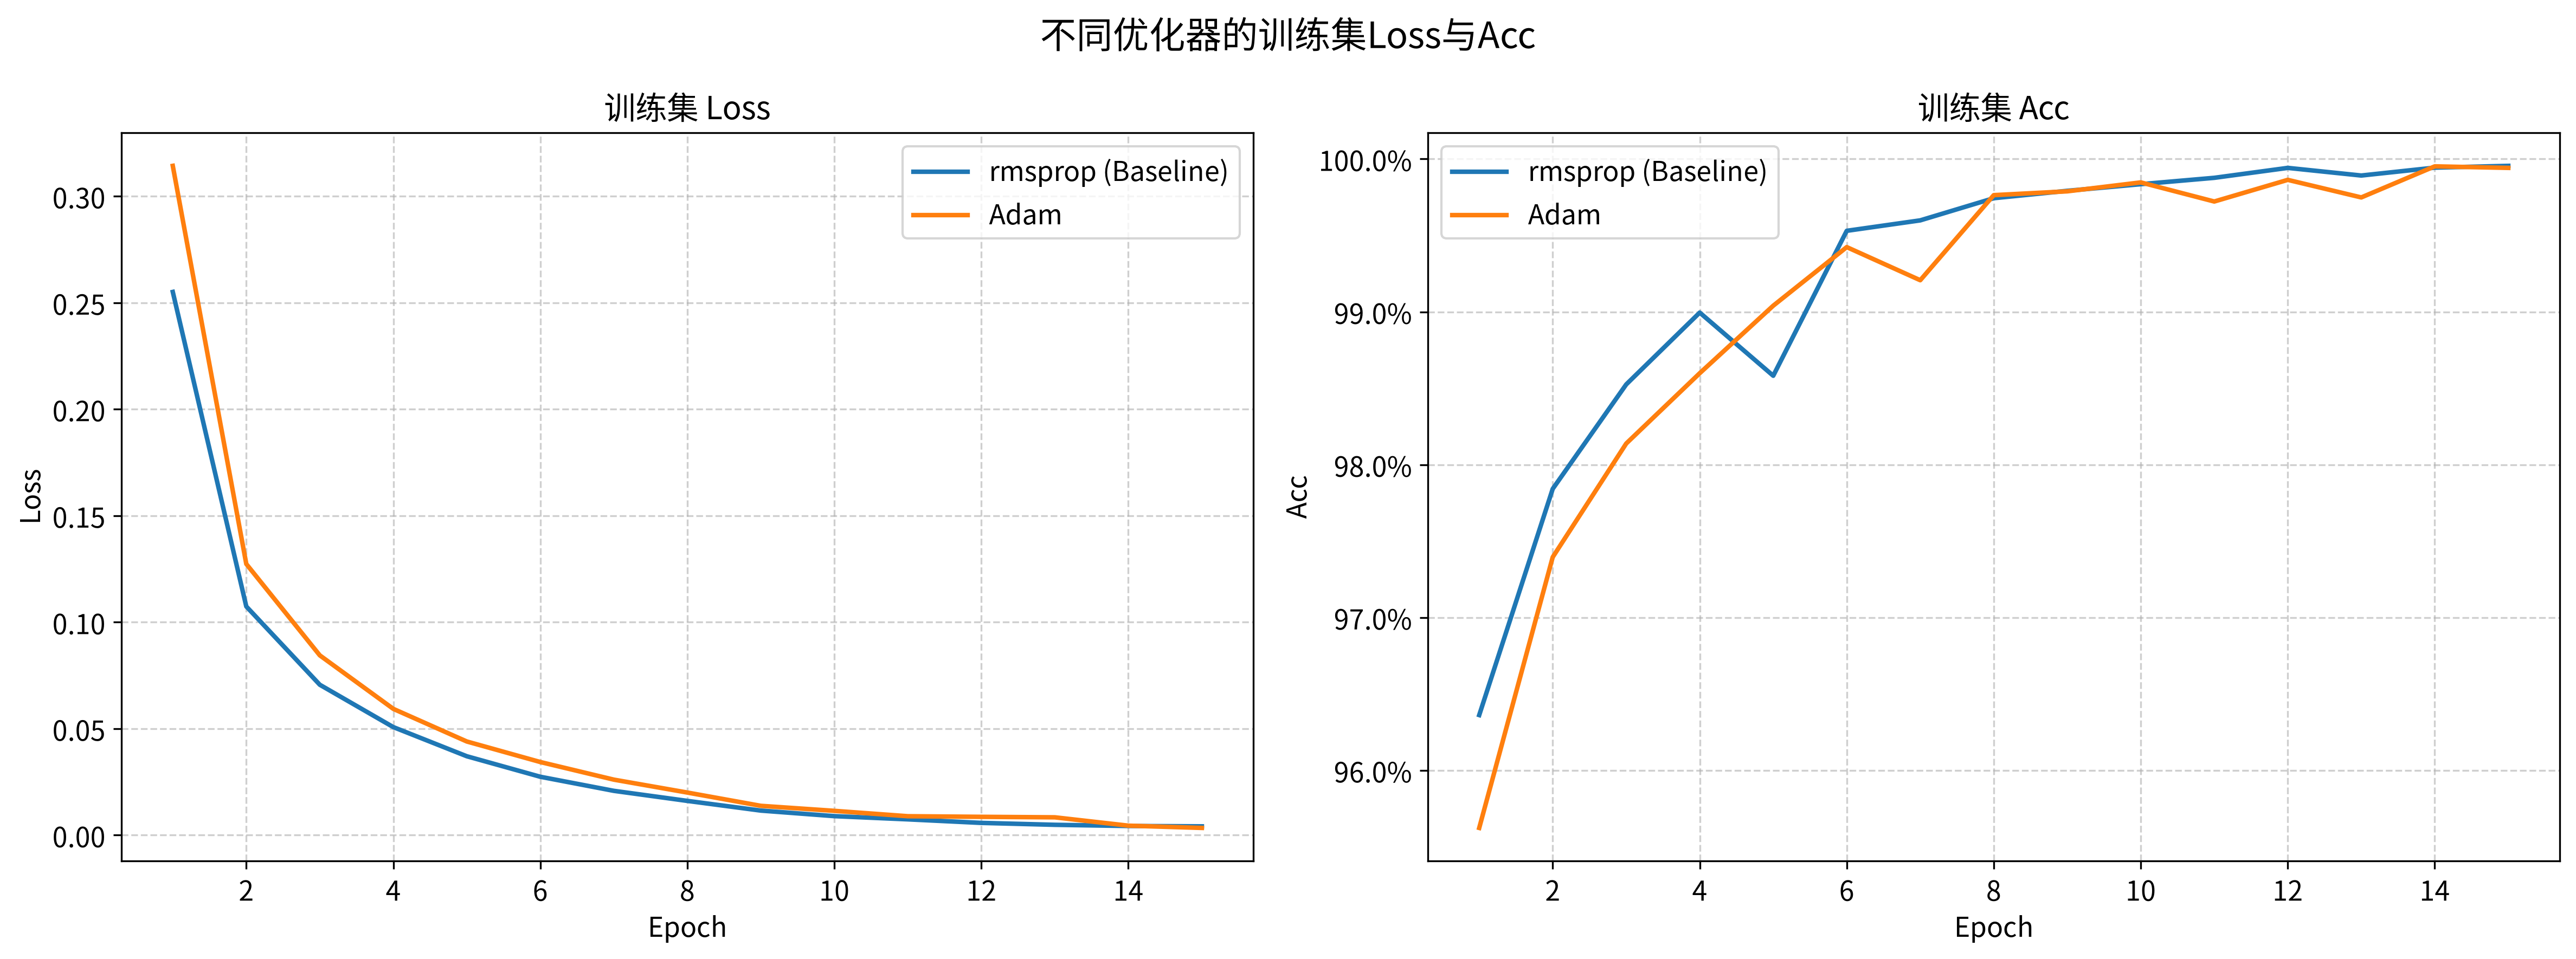

In [216]:
compare_data = {
    'rmsprop (Baseline)': train_result_df,
    'Adam': train_result_df1
}
plot_multiple_models_train_result(compare_data, title="不同优化器的训练集Loss与Acc")

测试集结果对比：

| | Baseline (RMSprop) | Adam |
| :---: | :---: | :---: |
| Loss | 0.0742 | 0.0682 |
| Acc | **98.20%** | 98.10% |

结论：简单任务中，RMSprop的效果更佳。
